# Phase 6C - Clustering: what shapes does the first month of a song take, and do artists come in types?

**Project:** United States Top 50 Playlist Performance and Song Popularity Trend Analysis (Atlantic Recording Corporation case)

**What this notebook does.** Phase 6B measured how long songs stay on the chart. This notebook looks at the *shape* of the first month. Take the 832 songs (by 223 artists) that arrived early enough for their whole first month to lie inside the file; the 62 songs that arrived in the last 29 snapshot days are left out, because their month is not finished and a song that is still on its way would look like a song that left. Every song becomes one row of 30 numbers: its *chart score* on each of its first 30 snapshot days, which is 51 minus its place on the chart (place 1 is a score of 50, place 50 is a score of 1) and 0 on a day when it is not on the chart. A clustering method then looks for songs whose rows look alike. In the second half the same idea is applied to the 243 artists, using their footprint on the chart (how many songs, how long they last, how high they sit, how many are on at once).

**A clustering method always returns groups, whether the data hold groups or not.** So most of the work of this notebook is not finding the groups but deciding how far to believe them. Three checks are used. First, the *artist bootstrap*: draw whole artists again with replacement, fit the grouping again, and see how much of the original grouping comes back. Songs of one artist are not independent of each other (an album drop is a dozen songs that arrive on the same day), so re-drawing songs one by one would flatter the result; Section 6 shows how much that changes a p-value, and Section 9 how alike the songs of one artist really are. Second, *held-out artists*: fit the grouping without some artists and see whether their songs land in the group they were put in before. Third, *stress runs*: change the method, the length of the month or the songs, and see whether the same groups appear. A group is called *firm* when, on average over the artist draws, its songs are found together again with a Jaccard score of at least 0.75 (explained in Section 3), and *dissolved* when the score is under 0.60.

**How the words are used.** An *archetype* is a group of songs with a similar first month. A *segment* is a group of artists with a similar footprint. The brief for this project is historical analytics, not prediction and not recommendation: the archetypes describe what the first months of 832 songs looked like, and Section 6 asks what went with them afterwards. They are not boxes into which a new song can be put with confidence, and every difference is an association among these songs.

**Before you run it.** Phases 1 to 6B must have run, so that `data/processed/` holds the Parquet tables (if not: `python -m src.etl.run_pipeline`) and `reports/p6b_stays.csv` exists (notebook 06b writes it; Section 6 uses its arrival-day risk thirds). `reports/p4_facts.json` is used for one cross-check if it is there. Then restart the kernel and choose *Run All*. In our test runs the whole notebook took one to one and a half minutes; a slower computer may need a few minutes. It writes 11 charts to `reports/figures/p6c_*.png` and these files to `reports/`: `p6c_facts.json` (every number quoted in the text), `p6c_k_scan_songs.csv`, `p6c_archetypes.csv`, `p6c_song_archetypes.csv` (one row per song), `p6c_first_months.csv` (the 30 chart scores of every song), `p6c_stability.csv`, `p6c_stress_tests.csv`, `p6c_landmark.csv`, `p6c_risk_thirds.csv`, `p6c_attributes.csv`, `p6c_k_scan_artists.csv`, `p6c_artist_segments.csv` (one row per segment), `p6c_artists.csv` (one row per artist) and `p6c_archetype_by_segment.csv` (the archetype mix of every artist segment). Always restart the kernel before running again: the container of numbers refuses to store the same name twice, which is how we know that no number is silently replaced.

**If your numbers differ a little.** The text was written from one run of this notebook, and the notebook was then run on three different sets of library versions (from pandas 2.2 with numpy 1.26 up to pandas 3.0 with numpy 2.5). All of the numbers it stores came out identical in the three runs except four, which are bootstrap scores in the artist scan on the oldest versions and differ after the third decimal; no sentence changes because of them. The reason is that the grouping, the bootstrap and the stress runs are written in numpy in `src/cluster` with fixed random seeds, and do not depend on a library's own clustering code. If a number on your screen still differs from the text, open `reports/p6c_facts.json`, which holds the numbers of your run. A difference in the last digit of a bootstrap score is harmless. A difference in a count (the 832 songs, say) means that the data or an earlier phase differs from ours, and Phases 3 to 6B should be run again first.

**How to read it.** Every code cell has a short plain-English explanation above it in five parts: *what this code is*, *why we need it*, *what will happen*, *expected outcome* and *motive*. Every chart has a *What to notice* note below it, and the numbers in those notes are not typed by hand: the code stores each number it computes in `FACTS`, and the sentences are written from it.

**Ground rules used throughout.**

- *One unit and one picture of a song.* The unit is the first 30 snapshot days of a song that arrived after the first snapshot. The picture is the chart score of every day. Section 5 tries other months and other pictures.
- *The artist is the unit of doubt.* Every re-draw, every held-out set and every band is made of whole artists, never of single songs.
- *No library hides the method.* The grouping method (k-means), the silhouette and the adjusted Rand index are written in a few lines of numpy in `src/cluster` and covered by tests, so that the groups come out the same on every setup.
- *Groups are descriptions, not species.* The first months of songs form a continuum with dense regions. The archetypes are the regions that stay put when the artists change; the notebook says which ones those are and which borders are soft.
- *Held fixed means in this data.* Nothing here says what would happen to a song if its first month were different.

| Section | What it does | Figures |
|---|---|---|
| 1 | Setup and loading | - |
| 2 | One row per song: the first month | 1 |
| 3 | How many groups of songs? | 2 |
| 4 | The archetypes | 3-4 |
| 5 | Are they firm? Artists re-drawn, artists held out, ten changes to the method | 5-6 |
| 6 | What the archetypes say about staying (the link to Phase 6B) | 7 |
| 7 | What goes with each archetype | 8 |
| 8 | Artists: do they come in types? | 9-10 |
| 9 | The two views together | 11 |
| 10 | Saving the results and what Phase 6C adds up to | - |

## Section 1 - Setup and loading

**What this code is.** The import cell. It loads the Python libraries (pandas for tables, numpy for numbers, matplotlib for charts) and our own modules: `src/cluster` (the first-month table, k-means, the silhouette, the adjusted Rand index, the artist bootstrap and the held-out artists, the artist table and the PCA) together with the helpers of Phases 3 to 6B for paths, the chart look, the container of facts, the artist draws and the survival curve.

**Why we need it.** Everything below uses these names. The logic that matters (how a first month becomes a row of numbers, how a grouping is judged) lives in `src/cluster` and is covered by automated tests, so the notebook stays short and the formulas stay checked. The two path lines make `from src...` work whether Jupyter was started in the project folder or in the `notebooks` folder.

**What will happen.** Python imports the libraries, switches on the project look and creates `FACTS`, where every number that appears in a sentence is stored once (it refuses to store a name twice and refuses numbers that are not finite). It then sets the settings of the whole notebook: a month of 30 snapshot days, a scan of 2 to 8 song groups, 300 artist draws for every group count of the scan and 1,000 for the chosen one, and 30 random starts for every fit.

**Expected outcome.** Four printed lines (the versions of pandas, numpy and scipy, and the project folder) and no chart. If a line fails with `ModuleNotFoundError`, run `pip install -r requirements.txt` in the project folder and restart the kernel.

**Motive.** One setup, one look, one place for the numbers. From here to the end no number in a sentence is typed by hand.

In [1]:
import hashlib
import json
import sys
import textwrap
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from matplotlib.lines import Line2D
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.optimize import linear_sum_assignment

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))            # makes "from src..." work when the notebook starts inside the notebooks folder

from src.cluster.artists import FEATURES, artist_matrix, artist_table, pca
from src.cluster.kmeans import adjusted_rand, assign, kmeans, match_labels, silhouette
from src.cluster.paths import first_month_matrix
from src.cluster.stability import artist_folds, bootstrap_stability, heldout_assignment
from src.config import default_paths
from src.eda import style
from src.eda.findings import Facts
from src.eda.plots import clean_text, direct_label, dot_row, make_fig, panel_title, save_fig, short, style_axes, swatch_legend
from src.inference.dependence import cluster_bootstrap_weights
from src.inference.register import format_p, save_table
from src.ml.dataset import build_modeling_table
from src.ml.models import SEED
from src.survival import plots as SP
from src.survival.estimators import logrank_k, median_further_stay, survival_grid
from src.survival.lives import GAP, build_lives, chart_with_snapshots

pd.set_option("display.max_columns", 40)             # show up to 40 columns instead of hiding some
pd.set_option("display.width", 200)                  # use a wide print area so that tables do not wrap
pd.set_option("display.float_format", "{:,.4g}".format)

style.apply_style()                                  # the project look: fonts, colours, hairline grid
FACTS = Facts()                                      # every number we quote in a sentence is stored here, once
STARTED = time.time()                                # the start of this run: Section 10 checks that every chart was written after it

HORIZON = 30                                         # the first month: 30 snapshot days, the arrival day is day 1
K_MAX = 8                                            # song groups are scanned from 2 to 8
N_BOOT_SCAN = 300                                    # artist draws for every group count of the scan
N_BOOT = 1000                                        # artist draws behind the chosen grouping
N_INIT = 30                                          # random starts of every k-means fit
N_INIT_BOOT = 5                                      # random starts inside every artist draw
FLOOR = 0.75                                         # a group is firm when, on average, at least 75% of its songs are found together again
DISSOLVED = 0.60                                     # below this a group has dissolved
FACTS["horizon"], FACTS["horizon_less_one"] = HORIZON, HORIZON - 1
FACTS["k_max"], FACTS["n_boot_scan"], FACTS["n_boot"], FACTS["n_init"], FACTS["n_init_boot"] = K_MAX, N_BOOT_SCAN, N_BOOT, N_INIT, N_INIT_BOOT
FACTS["floor"], FACTS["dissolved"] = FLOOR, DISSOLVED

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("scipy  :", scipy.__version__)
print("project:", PROJECT_ROOT)

pandas : 2.3.2
numpy  : 2.3.3
scipy  : 1.15.3
project: d:\INTERNSHIP PROJECTS\UNIFIED MENTOR WORK\PROJECT_2\United States Top 50 Playlist Performance and Song Popularity Trend Analysis Project\atlantic-top50-analytics


**What this code is.** The loading cell. It reads the four Parquet tables that the pipeline made (songs, chart rows, credits, calendar) and the table of stays that notebook 06b wrote. It stores the headline counts and compares them with Phase 4.

**Why we need it.** A grouping can only be as right as its data. If the pipeline had been changed since Phase 4, a quiet difference would flow into every number of this notebook. The comparison with `reports/p4_facts.json` stops the notebook, with a message that says what to run, if the chart is not the one that Phases 4 and 5 described. The table of 06b is needed in Section 6, and it is better to learn at the top that it is missing.

**What will happen.** The code checks that the files exist, reads them, stores the numbers of rows, songs and snapshot days and the first and last date in `FACTS`, and prints a small table. If `p4_facts.json` is there it compares song-days, songs and snapshot days with Phase 4 and stops on any difference.

**Expected outcome.** A table with 27,750 song-days, 944 songs and 555 snapshot days (from 18 May 2024 to 27 November 2025), followed by the line "Phase 4 reproduced: the same numbers of song-days, songs and snapshot days."

**Motive.** Be sure that Phase 6C looks at the same chart that Phases 4 to 6B described.

In [2]:
paths = default_paths()
FIG_DIR = paths.reports_dir / "figures"              # all charts of this notebook are saved here as PNG files
REPORT_DIR = paths.reports_dir

needed = ["dim_track", "fact_chart_daily", "bridge_track_artist", "dim_date"]
missing = [name for name in needed if not (paths.processed_dir / f"{name}.parquet").exists()]
assert not missing, f"Run the pipeline first:  python -m src.etl.run_pipeline   (missing: {missing})"
assert (REPORT_DIR / "p6b_stays.csv").exists(), "Run notebook 06b first: it writes reports/p6b_stays.csv, which Section 6 uses."

dim_track = pd.read_parquet(paths.processed_dir / "dim_track.parquet")                      # one row per song
fact_chart = pd.read_parquet(paths.processed_dir / "fact_chart_daily.parquet")              # one row per song per snapshot day
bridge = pd.read_parquet(paths.processed_dir / "bridge_track_artist.parquet")               # which artists are credited on which song
dim_date = pd.read_parquet(paths.processed_dir / "dim_date.parquet")                        # one row per calendar day
P6B = pd.read_csv(REPORT_DIR / "p6b_stays.csv", encoding="utf-8-sig")                       # one row per song that arrived after the first snapshot (Phase 6B)

snapshots = dim_date[dim_date["has_snapshot"]]
FACTS["rows"] = len(fact_chart)
FACTS["songs"] = len(dim_track)
FACTS["snapshots"] = len(snapshots)
FACTS["first_date"], FACTS["last_date"] = f"{snapshots['date'].min():%d %B %Y}", f"{snapshots['date'].max():%d %B %Y}"

display(pd.DataFrame({"table": ["fact_chart_daily (song x day)", "dim_track (songs)", "bridge_track_artist (credits)", "snapshot days"],
                      "rows": [len(fact_chart), len(dim_track), len(bridge), len(snapshots)]}))

# ---- the numbers of Phase 4 must come out again, otherwise this notebook would look at a different chart
p4_file = REPORT_DIR / "p4_facts.json"
if p4_file.exists():
    p4 = json.loads(p4_file.read_text(encoding="utf-8"))
    for label, now, before in [("song-days", len(fact_chart), p4["rows"]), ("songs", len(dim_track), p4["songs"]),
                               ("snapshot days", len(snapshots), p4["snapshots"])]:
        assert now == before, f"{label}: {now} here, {before} in Phase 4. Re-run the pipeline and notebook 04 first."
    print("Phase 4 reproduced: the same numbers of song-days, songs and snapshot days.")
else:
    print("reports/p4_facts.json is not there (notebook 04 has not been run): the cross-check with Phase 4 is skipped.")

,table,rows
0,fact_chart_daily (song x day),27750
1,dim_track (songs),944
2,bridge_track_artist (credits),1105
3,snapshot days,555


Phase 4 reproduced: the same numbers of song-days, songs and snapshot days.


**What this code is.** The cell that decides which songs are used and builds the table of first months. It takes the songs that arrived after the first snapshot (the *entrants*: only for them is the arrival day known), adds the facts of Phase 6B (where each song's first stay ended) and then calls `first_month_matrix`, which returns one row of 30 chart scores per song.

**Why we need it.** A song that arrived in the last 29 snapshot days has a first month that is cut off by the end of the file. Its row would end in zeros that mean "we stopped looking", and k-means would read them as "the song left". Only songs with a complete month are kept; the cell says how many are lost and when they arrived.

**What will happen.** The code builds the modelling table of Phase 6A, the chart with snapshot numbers and the stays of Phase 6B, and checks that these are the same 894 songs that 06b used. It builds the matrix, checks its shape and that the first column (the arrival day) is never zero, and stores the counts. It also stores how big the biggest artist is among the kept songs, because one artist with dozens of songs can pull a clustering towards itself; Section 5 tests that.

**Expected outcome.** 832 songs by 223 artists kept out of 894 entrants by 229 artists; 62 songs lost, all of them arrivals between 30 October 2025 and 27 November 2025. The biggest artist has 92 of the kept songs. A matrix of 832 rows and 30 columns, of which 38% of the cells are on the chart.

**Motive.** One row per song, the same columns for every song, and no song whose month is unfinished.

In [3]:
TABLE = build_modeling_table(dim_track, fact_chart, bridge, dim_date)        # the entrants: songs that arrived after the first snapshot day
CHART = chart_with_snapshots(fact_chart, dim_date)                           # track_id, snapshot number s, place on the chart
N_SNAPSHOTS = int(dim_date["has_snapshot"].sum())
LIVES = build_lives(CHART, TABLE["track_id"], N_SNAPSHOTS, gap=GAP)          # where the first stay of every entrant ends (Phase 6B)
STAYS = TABLE.merge(LIVES.drop(columns="entry_snapshot"), on="track_id", how="left")
assert len(STAYS) == len(P6B) and set(STAYS["track_id"]) == set(P6B["track_id"]), "the entrants differ from those of notebook 06b: re-run 06b"

M, KEPT = first_month_matrix(CHART, STAYS[["track_id", "entry_snapshot"]], N_SNAPSHOTS, horizon=HORIZON)
SONGS = STAYS.loc[KEPT].reset_index(drop=True)                               # the songs behind the rows of M, in the same order
ARTISTS = SONGS["primary_artist"].to_numpy()
assert M.shape == (len(SONGS), HORIZON) and (M[:, 0] > 0).all()              # the arrival day is a chart day for every song

dropped = STAYS.loc[~KEPT]
FACTS["n_entrants"], FACTS["n_entrant_artists"] = len(STAYS), STAYS["primary_artist"].nunique()
FACTS["n_kept"], FACTS["n_kept_artists"] = len(SONGS), len(set(ARTISTS))
FACTS["n_dropped"] = len(dropped)
FACTS["dropped_first"], FACTS["dropped_last"] = f"{dropped['entry_date'].min():%d %B %Y}", f"{dropped['entry_date'].max():%d %B %Y}"
per_artist = pd.Series(ARTISTS).value_counts()
FACTS["top_artist_songs"], FACTS["top_artist_name"] = int(per_artist.iloc[0]), str(per_artist.index[0])
FACTS["median_artist_songs"] = float(per_artist.median())
FACTS["cells_on_chart"] = float((M > 0).mean())

display(pd.DataFrame({"": ["entrants (arrived after the first snapshot)", "kept: whole first month inside the file", "lost: arrived in the last 29 snapshot days"],
                      "songs": [len(STAYS), len(SONGS), len(dropped)],
                      "artists": [STAYS["primary_artist"].nunique(), len(set(ARTISTS)), dropped["primary_artist"].nunique()]}).set_index(""))
print(f"matrix: {M.shape[0]} songs x {M.shape[1]} days; the biggest artist ({FACTS['top_artist_name']}) has {FACTS['top_artist_songs']} of the kept songs; "
      f"the median artist has {FACTS['median_artist_songs']:.0f}")

,songs,artists
,,
entrants (arrived after the first snapshot),894,229
kept: whole first month inside the file,832,223
lost: arrived in the last 29 snapshot days,62,22


matrix: 832 songs x 30 days; the biggest artist (Taylor Swift) has 92 of the kept songs; the median artist has 1


## Section 2 - One row per song: the first month

A song's first month is a list of 30 numbers. A song that arrives at place 5, holds the top 10 for three weeks and then drops out reads 46, 47, 48 ... and then zeros. A song that arrives at place 48 and is gone after two days reads 3, 2, 0, 0 ... Two songs are *close* when the lists are close: the distance between two songs is large when one is high on the chart while the other is away, and small when both are away. That is the whole idea of the representation; Section 5 checks that the result does not hang on this choice.

Before any grouping, the next cell and figure describe the rows as they are: how many of the 30 days a song spends on the chart, when it leaves, how many songs are still there on the last day.

**What this code is.** A first description of the table of first months, and Figure 1. For every song the cell counts the days on the chart (out of 30), the arrival place, the best place of the month and the last day on the chart. Figure 1 draws the whole table as a picture, one row per song (darker blue = higher on the chart, grey = not on the chart), with the songs sorted so that the long stays are at the top, next to a histogram of the number of chart days.

**Why we need it.** The groups of the next sections have to be read against the raw material. If the picture showed no structure at all, clustering would be pointless; if it showed a few obvious blocks, the clustering should find them. The picture is sorted by the number of chart days on purpose and *not* by any grouping, so it cannot be accused of showing what the method wanted.

**What will happen.** The code stores the share of songs that spend 3 chart days or fewer in the month, the share that are on the chart on all 30 days, the share still on the chart on day 30, the share that leave and come back inside the month (a gap in the middle of the row), and the median arrival place. It draws the table as a heat map and the histogram, and saves the picture as `p6c_01_first_months.png`.

**Expected outcome.** A picture that is dense at the top (songs that are on the chart nearly every day) and sparse at the bottom (songs that visit for a few days), with a visible block of songs that start low in the chart and rise. The histogram has one tall bar at the left (the songs that spend one to three days on the chart) and a second, lower bar at the right edge (the songs that are on the chart every day of the month).

**Motive.** Look at the data before grouping it, so that the groups can be judged against what the rows really look like.

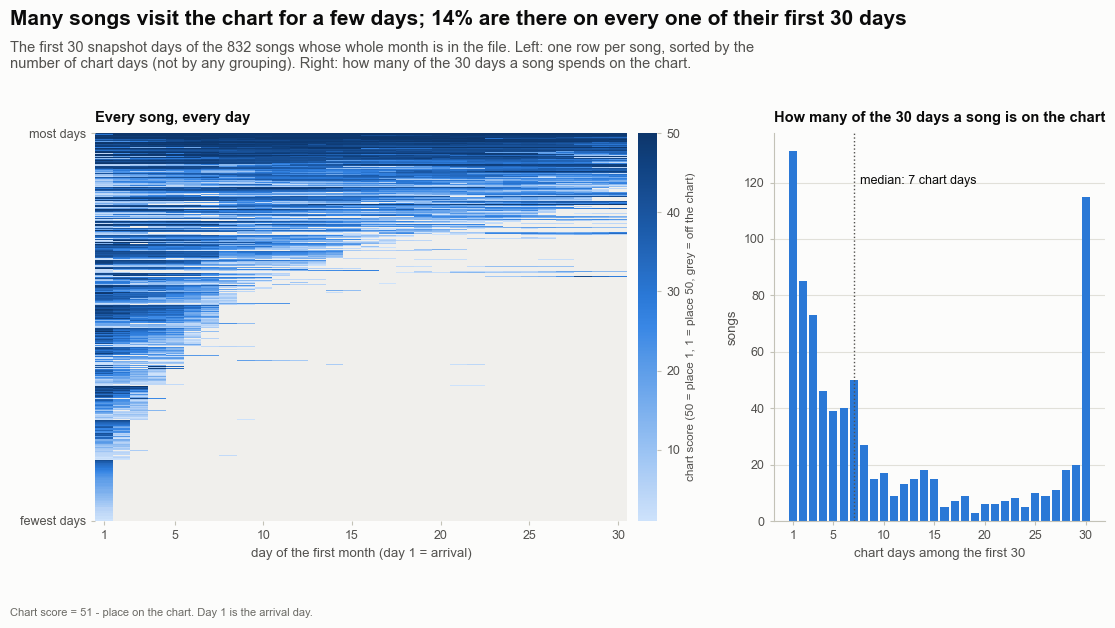

In [4]:
# Figure 01 - the first 30 days of every song, and how many chart days a song uses
ON = M > 0                                                                       # True on a day when the song is on the chart
DAYS_ON = ON.sum(axis=1)                                                         # chart days among the first 30
LAST_ON = np.where(ON.any(axis=1), HORIZON - np.argmax(ON[:, ::-1], axis=1), 0)  # the last day (1 to 30) on which the song is on the chart
DEBUT_PLACE = 51 - M[:, 0]                                                       # the place on the arrival day
BEST_PLACE = 51 - M.max(axis=1)                                                  # the best place of the month

FACTS["days_on_median"], FACTS["days_on_mean"] = float(np.median(DAYS_ON)), float(DAYS_ON.mean())
FACTS["share_3_days_or_fewer"] = float((DAYS_ON <= 3).mean())
FACTS["share_all_days"] = float((DAYS_ON == HORIZON).mean())
FACTS["share_on_last_day"] = float(ON[:, -1].mean())
FACTS["share_gap_inside"] = float(((LAST_ON - DAYS_ON) > 0).mean())              # absent on some day before the last chart day: left and came back
FACTS["debut_place_median"] = float(np.median(DEBUT_PLACE))
FACTS["share_debut_top10"] = float((DEBUT_PLACE <= 10).mean())
FACTS["share_debut_41_50"] = float((DEBUT_PLACE >= 41).mean())

order = np.lexsort((-M.mean(axis=1), -DAYS_ON))                                  # most chart days first; equal ones by their average score
cmap = style.SEQUENTIAL_BLUE.copy()
cmap.set_bad(style.NEUTRAL_MID)                                                  # a day off the chart is drawn in light grey

fig, (axa, axb) = make_fig(11.8, 6.4, 1, 2, left=1.2, right=0.5, bottom=0.95, wspace=0.26, width_ratios=[1.7, 1], panel_titles=True,
                           title=f"Many songs visit the chart for a few days; {100 * FACTS['share_all_days']:.0f}% are there on every one of their first {HORIZON} days",
                           subtitle=f"The first {HORIZON} snapshot days of the {len(SONGS)} songs whose whole month is in the file. Left: one row per song, sorted by the number of chart days "
                                    "(not by any grouping). Right: how many of the 30 days a song spends on the chart.",
                           note_text="Chart score = 51 - place on the chart. Day 1 is the arrival day.")
img = axa.imshow(np.where(M[order] > 0, M[order], np.nan), aspect="auto", cmap=cmap, vmin=1, vmax=50, interpolation="nearest")
axa.set_xticks([0, 4, 9, 14, 19, 24, 29])
axa.set_xticklabels([1, 5, 10, 15, 20, 25, 30])
axa.set_yticks([0, len(SONGS) - 1])
axa.set_yticklabels(["most days", "fewest days"])
axa.set_xlabel("day of the first month (day 1 = arrival)")
axa.tick_params(length=3, color=style.AXIS)
for side in axa.spines.values():
    side.set_visible(False)
bar = fig.colorbar(img, ax=axa, fraction=0.035, pad=0.02)
bar.set_label("chart score (50 = place 1, 1 = place 50, grey = off the chart)", fontsize=8.5, color=style.INK_2)
bar.outline.set_visible(False)
panel_title(axa, "Every song, every day")

counts = np.bincount(DAYS_ON, minlength=HORIZON + 1)[1:]
axb.bar(np.arange(1, HORIZON + 1), counts, color=style.BLUE, width=0.8)
axb.axvline(FACTS["days_on_median"], color=style.INK_2, linewidth=1.0, linestyle=":")
direct_label(axb, FACTS["days_on_median"] + 0.6, counts.max() * 0.92, f"median: {FACTS['days_on_median']:.0f} chart days", size=9, color=style.INK)
axb.set_xticks([1, 5, 10, 15, 20, 25, 30])
axb.set_xlabel("chart days among the first 30")
axb.set_ylabel("songs")
style_axes(axb, grid="y")
panel_title(axb, "How many of the 30 days a song is on the chart")
save_fig(fig, "p6c_01_first_months", FIG_DIR)
plt.show()

**What to notice**

- The picture is not a smear. The songs with few chart days are the largest part of it: 35% of the 832 songs spend three days or fewer on the chart in their first 30, and the median is 7 days. At the other end 14% are on the chart on every single day, and 21% are still there on day 30.
- The long stays are not all alike. Among the rows that reach the right edge some are dark from the first day (the songs arrived high) and some start pale and darken (the songs arrived low and climbed). A grouping that tells these two kinds apart, with the same number of days on the chart, is doing something that a count of days cannot; Section 4 puts numbers on it.
- A gap in the middle of a row is not rare: 19% of the songs are off the chart on at least one day before their last chart day inside the month. Songs near the bottom of the chart drop in and out. The representation counts such a day as a zero, which is what it was: a day without the song on the chart.
- Songs arrive anywhere on the chart. The median arrival place is 24; 24% arrive in the top 10 and 26% in places 41 to 50.

## Section 3 - How many groups of songs?

k-means needs to be told how many groups to look for, and it will find that many whatever the data look like. The honest way to choose is to ask, for each number of groups from 2 to 8, how well the groups hold up when the artists are drawn again. Three numbers are used.

- *The silhouette* of a grouping says how well every song fits its own group compared with the next-nearest group (from -1 to 1; above 0.5 is clear structure, 0.25 to 0.5 is weak structure, below 0.25 is none). It is computed on the songs as they are, and it is the traditional guide.
- *The adjusted Rand index (ARI)* between the original grouping and a re-fit on re-drawn artists says how much of the whole grouping comes back (1 = all of it, about 0 = nothing more than chance).
- *The Jaccard score of a group* says how much of one particular group comes back: take the songs of the group in the original grouping and the best-matching group of the re-fit; the score is the number of songs in both divided by the number in either (1 = exactly the same songs). The mean over the artist draws below 0.60 means the group dissolves; at 0.75 or above it is firm; in between the group is a pattern that is only partly re-found.

**The rule for the number of groups.** Count up from 2 groups. Stop at the first number of groups at which some group dissolves (its mean Jaccard score is below 0.60). Among the numbers of groups before that point, take the largest at which every group is firm (0.75 or more). The rule is cautious on purpose. It does not skip past a number of groups where something dissolves just because a larger number happens to pass again, and it uses the clear line (dissolved) to decide where to stop and the firm line only to choose among the numbers before it, so that a group that lands at 0.74 or 0.76 does not change the answer on its own. The rule was fixed after an exploratory look at the data, and the whole scan is shown, so that a reader who prefers another rule can apply it. The same rule is used for the artists in Section 8.

**What this code is.** The scan. For 2 to 8 groups it fits k-means on the 832 songs (30 random starts, the best kept), computes the silhouette, then draws artists again 300 times, re-fits, and records the adjusted Rand index and the Jaccard score of every group. It applies the rule above to get the number of groups, `K`.

**Why we need it.** The number of groups is the one choice in k-means that changes every result. A rule that is stated in the open, and judged by what survives a change of artists rather than by a picture, keeps the notebook from finding the number that looks best on the day.

**What will happen.** For every number of groups the code fits the grouping, runs the artist bootstrap of `src/cluster/stability.py` (every draw takes as many artists as there are, with replacement, re-fits with 5 random starts, and gives *all* original songs to the nearest new centre so that the two groupings can be compared on the same songs) and stores the silhouette, the mean and the 10th percentile of the ARI, the Jaccard score of the weakest group and the size of the smallest group. The result is one table, saved as `p6c_k_scan_songs.csv`, and the chosen `K`.

**Expected outcome.** The silhouette falls as groups are added (it is highest for two groups, because two coarse groups are easy to tell apart). The weakest group's Jaccard score stays well above 0.60 up to a number of groups in the middle of the range and then drops below it; `K` is the number just before the drop.

**Motive.** Choose the number of archetypes by what survives, not by what looks tidy.

In [5]:
def choose_k(table, floor, dissolved):
    """
    The rule. Count up from the smallest k and stop at the first k in which some group dissolves (mean Jaccard below `dissolved`).
    Among the k before that point take the largest one in which every group is firm (mean Jaccard at least `floor`).
    Returns (that k, the last k before the stop).
    """
    before_stop = []
    for row in table.itertuples():
        if row.weakest < dissolved:
            break
        before_stop.append(row)
    firm = [r.k for r in before_stop if r.weakest >= floor]
    return (max(firm) if firm else None), (before_stop[-1].k if before_stop else None)


rows, JACCARD_BY_K = [], {}
t0 = time.time()
for k in range(2, K_MAX + 1):
    fit = kmeans(M, k, n_init=N_INIT, seed=SEED)
    boot = bootstrap_stability(M, ARTISTS, fit.labels, fit.centers, n_boot=N_BOOT_SCAN, seed=SEED + k, n_init=N_INIT_BOOT)
    mean_jaccard = boot["jaccard"].mean(axis=0)
    JACCARD_BY_K[k] = mean_jaccard
    rows.append({"k": k, "silhouette": silhouette(M, fit.labels), "inertia": fit.inertia, "smallest_group": int(np.bincount(fit.labels).min()),
                 "ari_mean": boot["ari"].mean(), "ari_p10": np.percentile(boot["ari"], 10), "weakest": mean_jaccard.min(),
                 "firm_groups": int((mean_jaccard >= FLOOR).sum()), "dissolved_groups": int((mean_jaccard < DISSOLVED).sum())})
K_SCAN = pd.DataFrame(rows)
SCAN_SECONDS = time.time() - t0

K, K_STOP = choose_k(K_SCAN, FLOOR, DISSOLVED)
assert K is not None and K_STOP < K_MAX, "the rule never stopped, or stopped at once: look at the table"
FACTS["k"] = K
for r in K_SCAN.itertuples():
    FACTS[f"sil_k{r.k}"], FACTS[f"weakest_k{r.k}"], FACTS[f"ari_k{r.k}"] = float(r.silhouette), float(r.weakest), float(r.ari_mean)
    FACTS[f"smallest_k{r.k}"] = int(r.smallest_group)
FACTS["k_next"] = K_STOP + 1                                                  # the first number of groups in which a group dissolves
FACTS["sil_chosen"], FACTS["weakest_chosen"], FACTS["ari_chosen"] = FACTS[f"sil_k{K}"], FACTS[f"weakest_k{K}"], FACTS[f"ari_k{K}"]
FACTS["weakest_next"] = FACTS[f"weakest_k{K_STOP + 1}"]
FACTS["sil_best_k"] = int(K_SCAN.loc[K_SCAN["silhouette"].idxmax(), "k"])

shown = K_SCAN.rename(columns={"k": "groups", "silhouette": "silhouette", "smallest_group": "smallest group (songs)", "ari_mean": "ARI, mean over draws",
                               "ari_p10": "ARI, 10th percentile", "weakest": "weakest group, mean Jaccard", "firm_groups": "groups at or above 0.75",
                               "dissolved_groups": "groups below 0.60"}).drop(columns="inertia").set_index("groups")
display(shown)
save_table(K_SCAN.assign(chosen=K_SCAN["k"].eq(K)), REPORT_DIR / "p6c_k_scan_songs.csv")
print(f"Rule: the first number of groups in which a group dissolves (below {DISSOLVED}) is {K_STOP + 1}; before it, the largest number with every group firm is {K}  ({SCAN_SECONDS:.0f} seconds for the whole scan)")

,silhouette,smallest group (songs),"ARI, mean over draws","ARI, 10th percentile","weakest group, mean Jaccard",groups at or above 0.75,groups below 0.60
groups,,,,,,,
2,0.6137,166,0.9699,0.9502,0.9675,2,0
3,0.4528,147,0.905,0.8308,0.8701,3,0
4,0.4317,83,0.8982,0.7832,0.7543,4,0
5,0.4251,69,0.9286,0.7898,0.8219,5,0
6,0.3443,56,0.7115,0.603,0.4936,2,2
7,0.3573,31,0.7674,0.6461,0.6241,3,0
8,0.3479,29,0.8761,0.6757,0.7778,8,0


Rule: the first number of groups in which a group dissolves (below 0.6) is 6; before it, the largest number with every group firm is 5  (33 seconds for the whole scan)


**What this code is.** Figure 2, the scan in pictures. Left: the silhouette for 2 to 8 groups. Middle: the adjusted Rand index of the artist draws (the dot is the mean, the line reaches down to the 10th percentile). Right: the Jaccard score of the weakest group, with the 0.75 line (firm) and the 0.60 line (dissolved). The chosen number of groups is shaded.

**Why we need it.** The decision of Section 3 rests on the right-hand panel. The other two panels show what the more familiar guides would have said, so that the reader can see where they agree with the rule and where they do not.

**What will happen.** The code reads the scan table, draws three small panels with a common horizontal axis (the number of groups), marks the chosen `K`, writes the values next to the dots and saves the picture as `p6c_02_how_many_groups.png`.

**Expected outcome.** A silhouette that falls steadily, an ARI that stays high and then dips, and a weakest-group line that is above the 0.75 line for the small numbers of groups and drops below the 0.60 line shortly after the shaded number.

**Motive.** Show why 5 groups, and why not more.

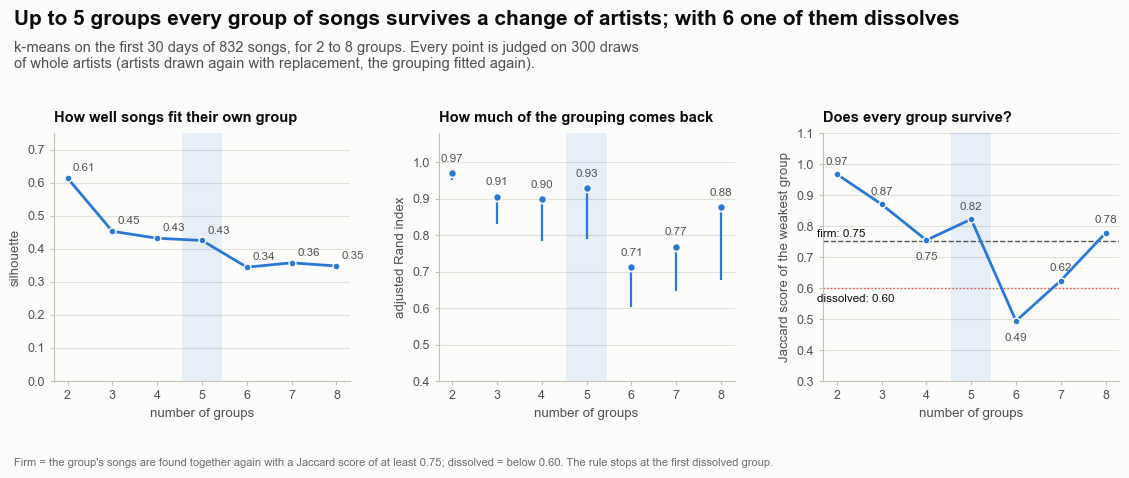

In [6]:
# Figure 02 - how many groups, and how well each choice stands up to a change of artists
fig, (axa, axb, axc) = make_fig(11.8, 4.9, 1, 3, left=0.75, right=0.4, bottom=0.85, wspace=0.3, panel_titles=True,
                                title=f"Up to {K} groups every group of songs survives a change of artists; with {K_STOP + 1} one of them dissolves",
                                subtitle=f"k-means on the first {HORIZON} days of {len(SONGS)} songs, for 2 to {K_MAX} groups. Every point is judged on {N_BOOT_SCAN} draws of whole artists "
                                         "(artists drawn again with replacement, the grouping fitted again).",
                                note_text=f"Firm = the group's songs are found together again with a Jaccard score of at least {FLOOR:.2f}; dissolved = below {DISSOLVED:.2f}. The rule stops at the first dissolved group.")
ks = K_SCAN["k"].to_numpy()
for ax in (axa, axb, axc):
    ax.axvspan(K - 0.45, K + 0.45, color=style.BLUE, alpha=0.10, linewidth=0)
    ax.set_xticks(ks)
    ax.set_xlabel("number of groups")
    style_axes(ax, grid="y")

axa.plot(ks, K_SCAN["silhouette"], color=style.BLUE, linewidth=2.0, marker="o", markersize=5, markeredgecolor=style.SURFACE)
for k, v in zip(ks, K_SCAN["silhouette"]):
    direct_label(axa, k + 0.12, v + 0.03, f"{v:.2f}", ha="left", size=8.4)
axa.set_ylim(0, 0.75)
axa.set_ylabel("silhouette")
panel_title(axa, "How well songs fit their own group")

axb.vlines(ks, K_SCAN["ari_p10"], K_SCAN["ari_mean"], color=style.BLUE, linewidth=1.6)
axb.scatter(ks, K_SCAN["ari_mean"], s=34, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=4)
for k, v in zip(ks, K_SCAN["ari_mean"]):
    direct_label(axb, k, min(v + 0.04, 1.02), f"{v:.2f}", ha="center", size=8.4)
axb.set_ylim(0.4, 1.08)
axb.set_ylabel("adjusted Rand index")
panel_title(axb, "How much of the grouping comes back")

axc.axhline(FLOOR, color=style.INK_2, linewidth=1.0, linestyle="--")
axc.axhline(DISSOLVED, color=style.RED, linewidth=1.0, linestyle=":")
direct_label(axc, ks[0] - 0.45, FLOOR + 0.025, "firm: 0.75", ha="left", size=8.4, color=style.INK)
direct_label(axc, ks[0] - 0.45, DISSOLVED - 0.035, "dissolved: 0.60", ha="left", size=8.4, color=style.INK)
axc.plot(ks, K_SCAN["weakest"], color=style.BLUE, linewidth=2.0, marker="o", markersize=5, markeredgecolor=style.SURFACE, zorder=4)
weak = K_SCAN["weakest"].to_numpy()
for i, (k, v) in enumerate(zip(ks, weak)):
    below = 0 < i < len(ks) - 1 and v < weak[i - 1] and v < weak[i + 1]                  # a dip is labelled underneath so that the label does not sit on the line
    direct_label(axc, k, v - 0.055 if below else v + 0.04, f"{v:.2f}", ha="center", size=8.4)
axc.set_ylim(0.3, 1.1)
axc.set_ylabel("Jaccard score of the weakest group")
panel_title(axc, "Does every group survive?")
save_fig(fig, "p6c_02_how_many_groups", FIG_DIR)
plt.show()

**What to notice**

- By the silhouette alone one would take 2 groups (0.61), the coarsest split, and every further group lowers it: 0.45 for three, 0.43 for four and 0.43 for 5. A silhouette of 0.43 is the weak-structure range: the first months of songs form a continuum with denser regions, not a set of islands. That is why the archetypes below are described as regions, and why the notebook asks whether the regions stay put rather than whether the clusters are "real".
- The weakest group of the 5-group solution has a mean Jaccard score of 0.82, above the 0.75 line, so all 5 groups are firm; with 6 groups the weakest falls to 0.49, below the 0.60 line, which means that one of the groups is re-found in fewer than two thirds of its songs when the artists change. With seven groups the weakest is 0.62, and with eight 0.78: every group is firm again, but the smallest has only 29 songs, and the rule does not reach over the failure at 6 groups. The number of groups is not the only soft spot: the four-group solution has a weakest group of 0.75, only just above the firm line, so one of the borders between neighbouring groups is already soft at four groups.
- The adjusted Rand index points the same way: the whole 5-group grouping comes back with an ARI of 0.93 on average, the 6-group grouping with 0.71, the lowest of the scan. The ARI says that something moved but not which group, because the big groups carry it; the Jaccard score of the weakest group names the trouble.
- The scan is quick because every artist draw re-fits with only 5 random starts; the chosen grouping is re-checked with 1,000 draws in Section 5.

## Section 4 - The archetypes

With 5 groups the 832 songs fall into the archetypes below. k-means numbers its groups by size and says nothing about what they are, so the next cell does two things: it describes every group in plain numbers (how high songs arrive, how many of the 30 days they spend on the chart, when they leave, where they are on day 30), and it gives every group a name by a *rule* written in code, with checks, so that a name cannot be attached to the wrong group if the data change. The names describe the first month only; they do not say anything about what happens after it (that is Section 6).

**What this code is.** The final fit and the profile. It fits k-means with 5 groups (30 random starts), computes the profile of every group, names the groups by rule, puts them in the order of the average number of chart days (shortest first) and finds the two songs closest to the centre of every group as examples. It saves the profile as `p6c_archetypes.csv`.

**Why we need it.** A grouping is only useful if people can talk about it. The profile gives every group a size, a typical arrival place, a typical length of stay and a position on day 30, and the rule for the names is stated in the code: the *slow climbers* are the only group whose average score on day 30 is higher than on day 1; the *lasting hits* are the group with the highest average score on day 30 among the rest; the other three are told apart by their number of chart days (*month-long fades* the most, *brief visitors* the fewest). The checks stop the notebook if a name would not describe its group.

**What will happen.** The code fits the grouping, builds the profile, applies the naming rule and runs the checks (the rule must name every group once; the slow climbers are the only group that gains between day 1 and day 30; the lasting hits are still on the chart on day 30 in more than nine cases out of ten; the month-long fades are mostly gone by day 30; the number of chart days increases from brief visitors to quick fades to month-long fades). It re-numbers the groups from 0 to 4 in the display order and stores the profile in `FACTS`.

**Expected outcome.** A table of 5 rows. The biggest group is the brief visitors (421 songs, 51% of all) who arrive low on the chart and are gone within about 4 days. The smallest groups are the slow climbers, the lasting hits and the month-long fades, with between 69 and 77 songs each. The two songs shown for every group are real songs of the group, the nearest to its centre.

**Motive.** Turn 5 anonymous groups into 5 archetypes that a reader can picture, with names that the data have to earn.

In [7]:
FIT = kmeans(M, K, n_init=N_INIT, seed=SEED)
assert K == 5 and K_STOP == 5, "the names of this section are written for five archetypes"
FACTS["k_less_one"] = K - 1


def raw_profile(labels):
    """The numbers that the names are based on, one row per group (the group numbers are those of k-means)."""
    rows = []
    for g in range(K):
        m = labels == g
        rows.append({"group": g, "songs": int(m.sum()), "days_on": float(DAYS_ON[m].mean()), "debut_score": float(M[m, 0].mean()),
                     "end_score": float(M[m, -1].mean()), "on_day_30": float(ON[m, -1].mean())})
    return pd.DataFrame(rows).set_index("group")


def name_groups(p):
    """
    The naming rule. Returns {group number: name}. Climbers: the only group whose average score is higher on day 30 than on day 1.
    Lasting hits: of the rest, the highest score on day 30. The three that remain are ordered by their chart days.
    """
    names = {}
    climber = (p["end_score"] - p["debut_score"]).idxmax()
    names[climber] = "Slow climbers"
    rest = [g for g in p.index if g != climber]
    lasting = p.loc[rest, "end_score"].idxmax()
    names[lasting] = "Lasting hits"
    rest = [g for g in rest if g != lasting]
    longest, middle, shortest = p.loc[rest, "days_on"].sort_values(ascending=False).index
    names[longest], names[middle], names[shortest] = "Month-long fades", "Quick fades", "Brief visitors"
    # ---- the checks: every name must describe its group
    gain = p["end_score"] - p["debut_score"]
    assert gain[climber] > 0 and (gain.drop(climber) < 0).all(), "the slow climbers must be the only group that gains between day 1 and day 30"
    assert p.loc[lasting, "on_day_30"] > 0.9, "the lasting hits must still be on the chart on day 30"
    assert p.loc[longest, "on_day_30"] < 0.5, "the month-long fades must be mostly gone by day 30"
    assert p.loc[shortest, "days_on"] < p.loc[middle, "days_on"] < p.loc[longest, "days_on"], "chart days must rise from brief visitors to month-long fades"
    return names


RAW = raw_profile(FIT.labels)
NAMES_BY_GROUP = name_groups(RAW)
DISPLAY = RAW.assign(name=pd.Series(NAMES_BY_GROUP)).sort_values("days_on")["name"].tolist()        # shortest stay first
assert DISPLAY == ["Brief visitors", "Quick fades", "Month-long fades", "Slow climbers", "Lasting hits"], DISPLAY
NAMES = DISPLAY
old_of_new = [next(g for g, n in NAMES_BY_GROUP.items() if n == name) for name in DISPLAY]            # k-means group number of every display position
LAB = np.empty(len(M), dtype=int)                                                                    # archetype of every song, 0 to 4 in the display order
for new, old in enumerate(old_of_new):
    LAB[FIT.labels == old] = new
CENTERS = FIT.centers[old_of_new]                                                                    # the centres in the same order
assert np.allclose(CENTERS[LAB[0]], FIT.centers[FIT.labels[0]])
ARCH_COLORS = style.CATEGORICAL[:K]                                                                  # one colour per archetype in every chart of the notebook
ARCH = np.array(NAMES)[LAB]

# ---- the profile
distance = ((M[:, None, :] - CENTERS[None, :, :]) ** 2).sum(axis=2)                                  # squared distance of every song to every centre
profile = []
for g, name in enumerate(NAMES):
    m = LAB == g
    artists_here = pd.Series(ARTISTS[m]).value_counts()
    nearest = np.flatnonzero(m)[np.argsort(distance[m, g])[:2]]
    on_30 = ON[m, -1]
    profile.append({"archetype": name, "songs": int(m.sum()), "share_of_songs": float(m.mean()), "artists": int(artists_here.size),
                    "biggest_artist": str(artists_here.index[0]), "biggest_artist_songs": int(artists_here.iloc[0]),
                    "debut_place": float(DEBUT_PLACE[m].mean()), "best_place": float(BEST_PLACE[m].mean()), "chart_days": float(DAYS_ON[m].mean()),
                    "last_chart_day_median": float(np.median(LAST_ON[m])), "on_chart_day_30": float(on_30.mean()),
                    "place_day_30_median": float(np.median(51 - M[m, -1][on_30])) if on_30.any() else float("nan"),
                    "score_day_1": float(M[m, 0].mean()), "score_day_30": float(M[m, -1].mean()),
                    "examples": "; ".join(SONGS.loc[nearest, "track_label"])})
PROFILE = pd.DataFrame(profile)
save_table(PROFILE, REPORT_DIR / "p6c_archetypes.csv")

for row in PROFILE.itertuples():
    key = row.archetype.split()[0].lower().replace("-", "_")      # brief, quick, month_long, slow, lasting
    FACTS[f"n_{key}"], FACTS[f"share_{key}"], FACTS[f"artists_{key}"] = row.songs, row.share_of_songs, row.artists
    FACTS[f"debut_{key}"], FACTS[f"best_{key}"], FACTS[f"days_{key}"] = row.debut_place, row.best_place, row.chart_days
    FACTS[f"lastday_{key}"], FACTS[f"day30_{key}"] = row.last_chart_day_median, row.on_chart_day_30
    FACTS[f"score1_{key}"], FACTS[f"score30_{key}"] = row.score_day_1, row.score_day_30
    FACTS[f"top_artist_share_{key}"] = row.biggest_artist_songs / row.songs
    FACTS[f"top_artist_name_{key}"] = row.biggest_artist
    if not np.isnan(row.place_day_30_median):
        FACTS[f"place30_{key}"] = row.place_day_30_median
for g, name in enumerate(NAMES):                                                  # the day on which the average group has lost half of its day-1 height (fading groups only)
    key = name.split()[0].lower().replace("-", "_")
    average = M[LAB == g].mean(axis=0)
    if key in ("brief", "quick", "month_long"):
        FACTS[f"half_day_{key}"] = int(np.argmax(average < average[0] / 2)) + 1
slow = NAMES.index("Slow climbers")
FACTS["slow_min_on_share"] = float(ON[LAB == slow][:, :15].mean(axis=0).min())    # the lowest share of the climbers on the chart on any of the first 15 days
brief = LAB == NAMES.index("Brief visitors")
long_brief = brief & (DAYS_ON >= 10)                                              # brief visitors that are on the chart for ten days or more, at the bottom
FACTS["n_brief_long"], FACTS["share_brief_long"] = int(long_brief.sum()), float(long_brief.sum() / brief.sum())
FACTS["brief_long_place"] = float(np.mean([51 - M[i][M[i] > 0].mean() for i in np.flatnonzero(long_brief)]))
sizes_sorted = sorted(PROFILE["songs"])
FACTS["n_smallest"], FACTS["n_third"] = sizes_sorted[0], sizes_sorted[2]

display(PROFILE.drop(columns=["share_of_songs", "score_day_1", "score_day_30", "biggest_artist_songs", "examples"]).set_index("archetype").rename(columns={
    "songs": "songs", "artists": "artists", "biggest_artist": "biggest artist", "debut_place": "arrives at place", "best_place": "best place",
    "chart_days": "chart days of 30", "last_chart_day_median": "last chart day (median)", "on_chart_day_30": "on the chart on day 30",
    "place_day_30_median": "place on day 30 (median, if on)"}))
display(PROFILE[["archetype", "examples"]].set_index("archetype"))                 # the two songs nearest to the centre of every group
pd.set_option("display.max_colwidth", 140)

,songs,artists,biggest artist,arrives at place,best place,chart days of 30,last chart day (median),on the chart on day 30,"place on day 30 (median, if on)"
archetype,,,,,,,,,
Brief visitors,421,174,Taylor Swift,33.55,30.67,4.321,2,0.05463,40
Quick fades,192,50,Taylor Swift,14.61,12.53,8.807,7,0.01562,47
Month-long fades,73,31,Taylor Swift,10.97,7.932,21.82,22,0.1233,43
Slow climbers,69,59,Fuerza Regida,39.26,14.74,28.49,30,0.8986,22
Lasting hits,77,45,Taylor Swift,9.792,2.792,29.94,30,0.974,14


,examples
archetype,
Brief visitors,Missin’ You Like This (Feat. Luke Combs) by Po...
Quick fades,thanK you aIMee by Taylor Swift; El Dorado by ...
Month-long fades,Sharpest Tool by Sabrina Carpenter; Coincidenc...
Slow climbers,Austin (Boots Stop Workin') by Dasha; One Of T...
Lasting hits,Lies Lies Lies by Morgan Wallen; CHIHIRO by Bi...


**What to notice**

- The five groups are very different in size. The brief visitors are half of all songs (421, 51%) and the quick fades another 23% (192); the month-long fades, the slow climbers and the lasting hits hold between 8% and 9% of the songs each (73, 69 and 77 songs). Most new songs on this chart do not last; the songs that do are a small, distinct group.
- Where a song arrives and how long it lasts go together, but not perfectly. Brief visitors arrive at place 34 on average and have 4.3 chart days of 30; quick fades arrive at 15 (the median one is gone after day 7); month-long fades arrive at 11 and are on the chart 21.8 days; lasting hits arrive at 10, reach 3 at best and are on the chart 29.9 of 30 days. The slow climbers break the pattern: they arrive furthest down the chart of all five groups (average place 39), reach place 15 at best, and are on the chart 28.5 days.
- On day 30 the picture is stark. 97% of the lasting hits and 90% of the slow climbers are still on the chart, at a median place of 14 and 22. Only 12% of the month-long fades, 5% of the brief visitors and 2% of the quick fades are.
- The groups are not one artist's doing, but some are concentrated. The quick fades are 192 songs by only 50 artists, and the biggest of them (Taylor Swift) owns 22% of the group; the slow climbers are the opposite, 69 songs by 59 artists, the biggest of them with 4%. Section 5 removes the biggest artists and caps every artist, to see whether the groups survive.
- The name "brief visitors" describes the group on average. 11% of its songs (48) are on the chart for ten days or more, but around place 41, so their score stays close to zero all month. They are visitors to the bottom of the chart rather than short visits; Section 5 asks whether a picture that counts only presence would separate them.

**What this code is.** Figure 3: the shape of every archetype. Left: the average chart score on each of the 30 days (a day off the chart counts as 0, so the line falls when songs leave). Right: the share of the group that is on the chart on each day. The same colour stands for the same archetype in every chart from here on.

**Why we need it.** The profile table gives single numbers. The shapes show what the numbers cannot: when each group leaves, and whether the climbers really climb from the start or only late.

**What will happen.** The code averages the rows of every group, draws the five lines with the project colours and a legend, and saves the picture as `p6c_03_archetype_shapes.png`.

**Expected outcome.** Two groups that start high (month-long fades and lasting hits) and then part ways; two that fall to zero within about two weeks (brief visitors and quick fades); one group (the slow climbers) that starts low and ends above where it began.

**Motive.** Let the reader see the archetypes before reading the tables about them.

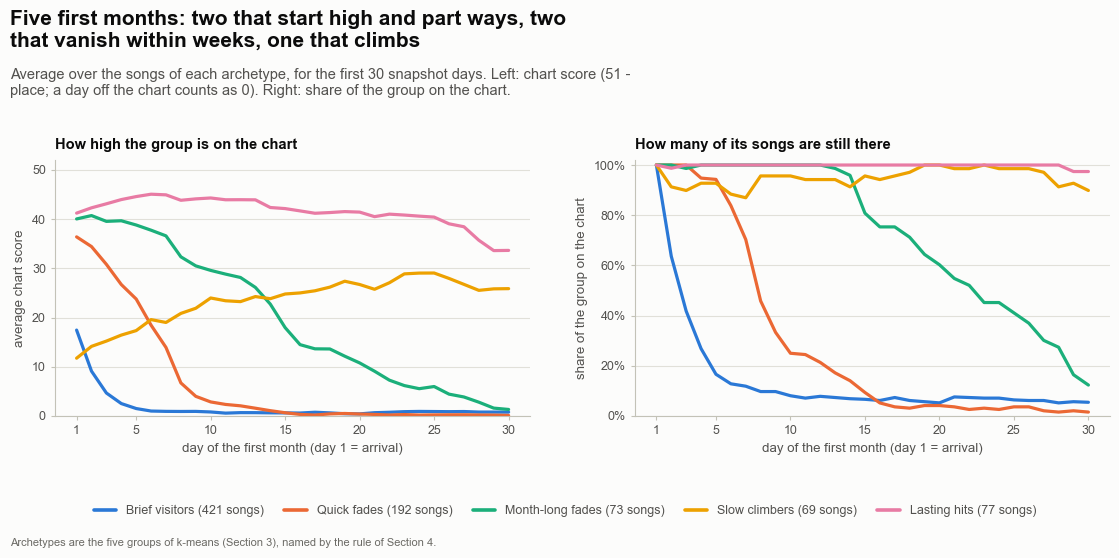

In [8]:
# Figure 03 - the average first month of each archetype
days = np.arange(1, HORIZON + 1)
fig, (axa, axb) = make_fig(11.8, 5.7, 1, 2, left=0.8, right=0.45, bottom=1.3, wspace=0.22, panel_titles=True,
                           title="Five first months: two that start high and part ways, two that vanish within weeks, one that climbs",
                           subtitle=f"Average over the songs of each archetype, for the first {HORIZON} snapshot days. Left: chart score (51 - place; a day off the chart counts as 0). Right: share of the group on the chart.",
                           note_text="Archetypes are the five groups of k-means (Section 3), named by the rule of Section 4.")
for g, name in enumerate(NAMES):
    axa.plot(days, M[LAB == g].mean(axis=0), color=ARCH_COLORS[g], linewidth=2.3, label=name)
    axb.plot(days, ON[LAB == g].mean(axis=0), color=ARCH_COLORS[g], linewidth=2.3)
axa.set_ylabel("average chart score")
axa.set_ylim(0, 52)
axb.set_ylabel("share of the group on the chart")
axb.set_ylim(0, 1.02)
axb.yaxis.set_major_formatter(SP.percent_axis)
for ax in (axa, axb):
    ax.set_xticks([1, 5, 10, 15, 20, 25, 30])
    ax.set_xlabel("day of the first month (day 1 = arrival)")
    style_axes(ax, grid="y")
fig.legend(handles=[Line2D([0], [0], color=ARCH_COLORS[g], linewidth=2.6, label=f"{name} ({int((LAB == g).sum())} songs)") for g, name in enumerate(NAMES)],
           loc="lower center", ncol=K, frameon=False, fontsize=9.0, bbox_to_anchor=(0.5, 0.055), handlelength=1.8, columnspacing=1.6)
panel_title(axa, "How high the group is on the chart")
panel_title(axb, "How many of its songs are still there")
save_fig(fig, "p6c_03_archetype_shapes", FIG_DIR)
plt.show()

**What to notice**

- Three groups fade, at three speeds. The average brief visitor has lost half of its first-day height by day 3, the average quick fade by day 7 and the average month-long fade by day 15. Month-long fades start as high as lasting hits (an average score of 40 against 41): the first week does not tell them apart, the second and third do.
- The lasting hits are the only group that stays near its starting height (41 on day 1, 34 on day 30; a score of 34 is place 17), and the share of them on the chart is close to 100% on every day.
- The slow climbers are not a smooth climb. Their average score rises from 12 to 26, but in the first two weeks as few as 87% of them are on the chart on one day: they start where a song drops in and out of the chart, and the ones that stay come up.

**What this code is.** Figure 4: all 832 songs, one row each, grouped by archetype (the same picture as Figure 1, now sorted by the grouping). Within a group the songs are sorted by their number of chart days. White lines separate the groups.

**Why we need it.** An average can hide a group that is really two kinds of song. The picture shows every song, so the spread inside every archetype can be seen, and so can the songs that look more like a neighbouring group than their own.

**What will happen.** The code orders the rows by archetype and chart days, draws them as a heat map with the same colours as Figure 1 and writes the name and size of every archetype on the left. It saves the picture as `p6c_04_archetype_songs.png`.

**Expected outcome.** Five bands. The top two are mostly light grey with a short coloured start; the next two are coloured for most of the month; the last band starts light and darkens to the right.

**Motive.** Show the raw material behind every average, so that the archetypes can be judged by eye as well as by number.

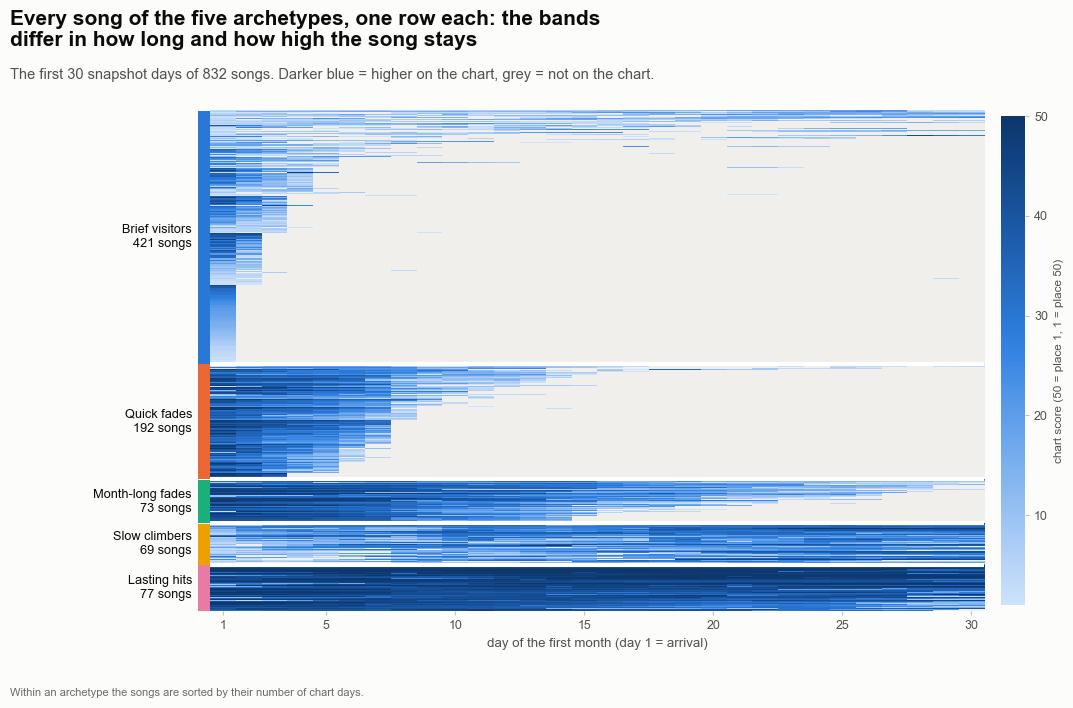

In [9]:
# Figure 04 - every song of the first month, grouped by archetype
parts = []
for g in range(K):
    idx = np.flatnonzero(LAB == g)
    parts.append(idx[np.lexsort((-M[idx].mean(axis=1), -DAYS_ON[idx]))])
ordering = np.concatenate(parts)
sizes = np.array([len(p) for p in parts])
edges = np.cumsum(sizes)

fig, ax = make_fig(11.8, 7.2, 1, 1, left=2.35, right=1.3, bottom=0.85,
                   title="Every song of the five archetypes, one row each: the bands differ in how long and how high the song stays",
                   subtitle=f"The first {HORIZON} snapshot days of {len(SONGS)} songs. Darker blue = higher on the chart, grey = not on the chart.",
                   note_text="Within an archetype the songs are sorted by their number of chart days.")
img = ax.imshow(np.where(M[ordering] > 0, M[ordering], np.nan), aspect="auto", cmap=cmap, vmin=1, vmax=50, interpolation="nearest")
for e in edges[:-1]:
    ax.axhline(e - 0.5, color="white", linewidth=3.0)
for g, (end, size) in enumerate(zip(edges, sizes)):
    ax.text(-1.2, end - size / 2, f"{NAMES[g]}\n{size} songs", ha="right", va="center", fontsize=9.2, color=style.INK)
    ax.add_patch(plt.Rectangle((-0.95, end - size + 0.5), 0.45, size - 1, color=ARCH_COLORS[g], clip_on=False, transform=ax.transData))
ax.set_xticks([0, 4, 9, 14, 19, 24, 29])
ax.set_xticklabels([1, 5, 10, 15, 20, 25, 30])
ax.set_yticks([])
ax.set_xlabel("day of the first month (day 1 = arrival)")
ax.tick_params(length=3, color=style.AXIS)
for side in ax.spines.values():
    side.set_visible(False)
bar = fig.colorbar(img, ax=ax, fraction=0.03, pad=0.02)
bar.set_label("chart score (50 = place 1, 1 = place 50)", fontsize=8.5, color=style.INK_2)
bar.outline.set_visible(False)
save_fig(fig, "p6c_04_archetype_songs", FIG_DIR)
plt.show()

**What to notice**

- Each band is uniform in the way that matters for its name: the lasting hits are dark almost everywhere, the quick fades are dark at the start and end between day 3 and day 10, the month-long fades fade between day 10 and day 30, and the slow climbers are pale at the left and dark at the right.
- The widest spread is in the brief visitors, the biggest band. Its bottom part is songs that come for a day or two (mostly dark at day 1, from songs that arrive high and are gone immediately); its top part is songs that stay but sit near place 50 (pale all month). Both are close to zero for most of the month, which is why k-means puts them together; the difference between them is in the arrival day, and Section 7 shows what goes with it.
- Between the bands there are songs that could belong to either side, for example the top rows of the quick fades that stay on the chart a few days longer than most. Section 5 counts how many songs are on a border like that.

## Section 5 - Are the archetypes firm?

Section 3 chose the number of groups with 300 artist draws and a cheap re-fit. This section examines the chosen grouping properly, in three ways. The *artist bootstrap* with 1,000 draws says how much of each archetype is found again when the artists change, and which songs sit on a border. The *held-out artists* check fits the grouping without a fifth of the artists and asks where the songs of those artists land. The *stress runs* change the method, the length of the month, the picture of a song or the songs themselves, and ask whether the same archetypes appear.

**What this code is.** The artist bootstrap and the held-out check on the chosen grouping. The bootstrap draws whole artists with replacement 1,000 times, fits k-means again on each draw (5 random starts), gives every original song to the nearest new centre, matches the new groups to the old ones and records the Jaccard score of every archetype, the adjusted Rand index of the whole grouping and, for every song, how often it lands in its own archetype. The held-out check deals the artists into five folds of about the same number of songs (an artist is never split), fits on four folds, assigns the songs of the fifth to the nearest centre, and repeats this ten times with different folds.

**Why we need it.** An archetype that exists only because of two or three artists would be an accident of this chart. Re-drawing artists asks directly: if the artists on the chart had been a different draw of the same kind, would the archetype still be there? Holding artists out asks the question a user would ask: would a song of an artist the grouping has never seen end up in the group that it ended up in here?

**What will happen.** The code runs both checks, stores the Jaccard score of every archetype (mean and 95% range over the draws), the share of draws in which an archetype dissolves, the share of songs that stay in their archetype in at least 90% of the draws and the share that do so in fewer than 60%, and the held-out results (the ARI of the whole grouping and, for every archetype, the share of its songs that land in it again). It saves a table, `p6c_stability.csv`.

**Expected outcome.** All five archetypes have a mean Jaccard score above 0.75, with the brief visitors and the quick fades the firmest and the slow climbers and the month-long fades the weakest (their borders touch other groups). Most songs are in their own archetype in nearly every draw; a minority sit on borders. The held-out check agrees with the bootstrap and is, if anything, kinder, because every fit keeps four fifths of the artists.

**Motive.** Know which archetypes to rely on and which songs are doubtful before any claim is made about them.

In [ ]:
t0 = time.time()
BOOT = bootstrap_stability(M, ARTISTS, LAB, CENTERS, n_boot=N_BOOT, seed=SEED, n_init=N_INIT_BOOT)
HELD = heldout_assignment(M, ARTISTS, LAB, CENTERS, n_folds=5, n_repeats=10, seed=SEED, n_init=N_INIT_BOOT)
CHECK_SECONDS = time.time() - t0

jaccard = BOOT["jaccard"]                                                         # (draws, archetypes)
AGREE = BOOT["agree"]                                                             # for every song: the share of draws that put it in its own archetype
FACTS["boot_ari_mean"], FACTS["boot_ari_p10"], FACTS["boot_ari_min"] = float(BOOT["ari"].mean()), float(np.percentile(BOOT["ari"], 10)), float(BOOT["ari"].min())
FACTS["held_ari_mean"], FACTS["held_ari_min"] = float(HELD["ari"].mean()), float(HELD["ari"].min())
FACTS["held_same_mean"], FACTS["held_same_min"] = float(HELD["same"].mean()), float(HELD["same"].min())
FACTS["share_agree_90"], FACTS["share_agree_below_60"] = float((AGREE >= 0.9).mean()), float((AGREE < 0.6).mean())
FACTS["n_agree_below_60"] = int((AGREE < 0.6).sum())

stability_rows = []
for g, name in enumerate(NAMES):
    key = name.split()[0].lower().replace("-", "_")
    m = LAB == g
    row = {"archetype": name, "songs": int(m.sum()), "jaccard_mean": float(jaccard[:, g].mean()), "jaccard_low": float(np.percentile(jaccard[:, g], 2.5)),
           "jaccard_high": float(np.percentile(jaccard[:, g], 97.5)), "share_of_draws_dissolved": float((jaccard[:, g] < DISSOLVED).mean()),
           "mean_agreement": float(AGREE[m].mean()), "share_songs_agree_90": float((AGREE[m] >= 0.9).mean()), "share_songs_agree_below_60": float((AGREE[m] < 0.6).mean()),
           "heldout_recall_mean": float(HELD["recall"][:, g].mean()), "heldout_recall_min": float(HELD["recall"][:, g].min()), "heldout_recall_max": float(HELD["recall"][:, g].max())}
    stability_rows.append(row)
    for field in ("jaccard_mean", "jaccard_low", "jaccard_high", "share_of_draws_dissolved", "mean_agreement", "share_songs_agree_90", "share_songs_agree_below_60",
                  "heldout_recall_mean", "heldout_recall_min"):
        FACTS[f"{field}_{key}"] = row[field]
STABILITY = pd.DataFrame(stability_rows)
save_table(STABILITY, REPORT_DIR / "p6c_stability.csv")
weakest_name = STABILITY.loc[STABILITY["jaccard_mean"].idxmin(), "archetype"]
firmest_name = STABILITY.loc[STABILITY["jaccard_mean"].idxmax(), "archetype"]
FACTS["weakest_name"], FACTS["firmest_name"] = weakest_name, firmest_name
FACTS["weakest_jaccard"], FACTS["firmest_jaccard"] = float(STABILITY["jaccard_mean"].min()), float(STABILITY["jaccard_mean"].max())
assert (STABILITY["jaccard_mean"] >= FLOOR).all(), "an archetype of the chosen grouping is not firm"

display(STABILITY.drop(columns=["songs"]).set_index("archetype").rename(columns={
    "jaccard_mean": "Jaccard, mean", "jaccard_low": "2.5%", "jaccard_high": "97.5%", "share_of_draws_dissolved": "draws in which it dissolves",
    "mean_agreement": "songs in own group, mean", "share_songs_agree_90": "songs in own group in 90%+ of draws", "share_songs_agree_below_60": "songs in own group in under 60%",
    "heldout_recall_mean": "held-out artists: songs back in group", "heldout_recall_min": "worst of 10 repeats", "heldout_recall_max": "best of 10 repeats"}))
print(f"artist bootstrap ARI {FACTS['boot_ari_mean']:.3f} (10th percentile {FACTS['boot_ari_p10']:.3f}); held-out artists: ARI {FACTS['held_ari_mean']:.3f}, "
      f"{100 * FACTS['held_same_mean']:.1f}% of songs back in their archetype  ({N_BOOT} draws and 10 x 5 held-out fits in {CHECK_SECONDS:.0f} seconds)")

**What this code is.** Figure 5, the three checks in pictures. Left: the Jaccard score of every archetype over the 1,000 artist draws (dot = mean, line = middle 95%), with the firm line and the dissolved line. Middle: for every archetype, how many of its songs are in their own archetype in at least 90% of the draws, in 60% to 90% of the draws, or in fewer than 60% (the songs on a border). Right: the share of every archetype's songs that land in it again when their artists are held out (dot = mean of ten repeats, line = worst to best).

**Why we need it.** The table has the numbers; the picture shows which archetype is the weak spot and whether it is weak because the whole group moves or because a few songs sit on the border.

**What will happen.** The code draws three panels with one row for each archetype, using the colour of the archetype for the dots and one blue and one orange for the three kinds of songs in the middle panel, and saves the picture as `p6c_05_stability.png`.

**Expected outcome.** Dots to the right of the firm line for every archetype; short lines for the big groups and long ones for the small groups; a middle panel dominated by the darkest blue with a thin orange end; held-out dots close to the right edge.

**Motive.** Show how far each archetype can be trusted, in one picture.

In [ ]:
# Figure 05 - how firm each archetype is
fig, (axa, axb, axc) = make_fig(11.8, 5.5, 1, 3, left=1.55, right=0.45, bottom=1.35, wspace=0.34, panel_titles=True, width_ratios=[1, 1.05, 1],
                                title=f"All five archetypes are found again when artists are re-drawn or held out; the least firm is {weakest_name.lower()}",
                                subtitle=f"{N_BOOT} draws of whole artists (left, middle) and ten repeats of holding out a fifth of the artists (right). Archetypes are in the order of their number of chart days.",
                                note_text=f"Firm = Jaccard score of at least {FLOOR:.2f}; dissolved = below {DISSOLVED:.2f}. Border songs are in their own archetype in fewer than 60% of the draws.")
y = np.arange(K)
for ax in (axa, axb, axc):
    ax.set_yticks(y)
    ax.set_ylim(K - 0.5, -0.5)
    style_axes(ax, grid="x", left_spine=False)
    ax.tick_params(axis="y", length=0)
axa.set_yticklabels(NAMES)
axb.set_yticklabels([])
axc.set_yticklabels([])

axa.axvline(FLOOR, color=style.INK_2, linewidth=1.0, linestyle="--")
axa.axvline(DISSOLVED, color=style.RED, linewidth=1.0, linestyle=":")
for g in range(K):
    axa.hlines(g, STABILITY.loc[g, "jaccard_low"], STABILITY.loc[g, "jaccard_high"], color=ARCH_COLORS[g], linewidth=5, alpha=0.5)
    axa.scatter([STABILITY.loc[g, "jaccard_mean"]], [g], s=46, color=ARCH_COLORS[g], edgecolor=style.SURFACE, linewidth=1.3, zorder=4)
    direct_label(axa, 1.02, g, f"{STABILITY.loc[g, 'jaccard_mean']:.2f}", size=8.8, color=style.INK)
axa.set_xlim(0.45, 1.1)
axa.set_xticks([0.5, 0.6, 0.75, 0.9, 1.0])
axa.set_xlabel("Jaccard score of the archetype")
panel_title(axa, "Is the group found again?")

colors3 = [style.BLUE_STEPS[650], style.BLUE_STEPS[250], style.ORANGE]
for g in range(K):
    a = AGREE[LAB == g]
    parts3 = [float((a >= 0.9).mean()), float(((a >= 0.6) & (a < 0.9)).mean()), float((a < 0.6).mean())]
    left = 0.0
    for part, color in zip(parts3, colors3):
        axb.barh(g, part, left=left, color=color, height=0.62, edgecolor="none")
        left += part
    if parts3[2] >= 0.03:
        direct_label(axb, 1.015, g, f"{100 * parts3[2]:.0f}% on a border", size=8.4, color=style.INK)
axb.set_xlim(0, 1.0)
axb.xaxis.set_major_formatter(SP.percent_axis)
axb.set_xlabel("share of the archetype's songs")
fig.legend(handles=[Line2D([0], [0], marker="s", linestyle="none", markersize=8, markerfacecolor=c, markeredgecolor=c, label=t)
                    for c, t in zip(colors3, ["song in its own archetype in 90% or more of the draws", "in 60% to 90% of the draws", "in under 60% of the draws (border song)"])],
           loc="lower center", ncol=3, frameon=False, fontsize=8.8, bbox_to_anchor=(0.5, 0.075), columnspacing=1.8, handletextpad=0.4)
panel_title(axb, "How many songs sit on a border?")

for g in range(K):
    axc.hlines(g, STABILITY.loc[g, "heldout_recall_min"], STABILITY.loc[g, "heldout_recall_max"], color=ARCH_COLORS[g], linewidth=5, alpha=0.5)
    axc.scatter([STABILITY.loc[g, "heldout_recall_mean"]], [g], s=46, color=ARCH_COLORS[g], edgecolor=style.SURFACE, linewidth=1.3, zorder=4)
    direct_label(axc, 1.012, g, f"{100 * STABILITY.loc[g, 'heldout_recall_mean']:.0f}%", size=8.8, color=style.INK)
axc.set_xlim(0.5, 1.06)
axc.xaxis.set_major_formatter(SP.percent_axis)
axc.set_xlabel("share of the archetype's songs that land in it again")
panel_title(axc, "Do unseen artists' songs land in it?")
save_fig(fig, "p6c_05_stability", FIG_DIR)
plt.show()

**What to notice**

- All five archetypes are firm on average. The mean Jaccard scores are 0.97 for the brief visitors, 0.91 for the quick fades, 0.82 for the month-long fades, 0.83 for the slow climbers and 0.90 for the lasting hits, and the whole grouping comes back with an adjusted Rand index of 0.93 (10th percentile 0.80). The brief visitors are the firmest; the month-long fades are the weakest, at 0.82.
- Firm on average is not firm in every draw. The month-long fades dissolve (a Jaccard score under 0.60) in 20% of the draws and the slow climbers in 13%: in those draws the artists happened to be such that the group is split or absorbed by a neighbour. The other three dissolve in at most 3% of the draws. If one archetype has to be treated with care, it is one of these two.
- The doubt is on the borders, not in the middle. 85% of the songs are in their own archetype in at least 90% of the draws, and only 12 songs (1.4%) in fewer than 60%. The month-long fades have the fewest songs that are firmly in place (51% are in the group in 90% or more of the draws), then the slow climbers (64%); the brief visitors have 96%.
- Songs of artists the grouping has not seen land where they should. With a fifth of the artists left out of every fit, 98.9% of the held-out songs land in their own archetype (the adjusted Rand index is 0.98 and never under 0.97 in ten repeats). All the lasting hits come back (100%), nearly all brief visitors (99.6%) and quick fades (99.6%); the slow climbers are the least certain (94% on average, 87% in the worst repeat). This test is kinder than the bootstrap because every fit keeps four fifths of the artists, while a bootstrap draw contains only about 63% of them (the rest are repeated).
- What this does and does not show. It shows that the five regions are not an accident of the artists in this file. It does not show that a new song will fall into one of them with certainty: a song on a border (the 12 above, and many more in the month-long fades and slow climbers) can be in either of two groups, and the file has to be read that way.

**What this code is.** The stress runs. Ten changes, each followed by the question: does the same grouping come out? (1) Another random start of k-means. (2) The 5 groups are fitted without the ten artists with the most songs, and every song is then given to the nearest centre. (3) Every artist is capped at eight songs for the fit (the eight are chosen by a fixed pseudo-random order, ten times with ten different orders, and the results are averaged), and every song is then given to the nearest centre. (4) Ward's hierarchical method instead of k-means. (5) A picture of a song that counts only presence (1 on a chart day, 0 off it) and ignores the place. (6) The chart score on a logarithmic scale, which shrinks the difference between high places. (7) A first month of 21 days instead of 30 (more songs qualify). (8) A first month of 45 days (fewer songs qualify). (9) 4 groups instead of 5. (10) 6 groups instead of 5. For each change the code stores the adjusted Rand index between the new grouping and the main one on the songs that both use; for the changes that keep 5 groups it also stores the share of songs that land in the matching group.

**Why we need it.** The bootstrap changes the artists and keeps the method. A reader who doubts the method needs the opposite test: keep the artists, change the method. If the archetypes were an artefact of the k-means algorithm, of the length of the month, of the scale of the score or of a few dominant artists, one of these changes would break them.

**What will happen.** The code runs the ten changes and prints one table; changes 9 and 10 are not stress tests in the same sense (a different number of groups cannot match one-to-one) but they show whether the neighbouring solutions are refinements of the main one. The table is saved as `p6c_stress_tests.csv`.

**Expected outcome.** An ARI of almost exactly 1 for the second random start, and a high ARI (about 0.9 or more) for the cap on the artists, the 21-day month and Ward's method. Lower values for the changes that remove 40% of the songs, lengthen the month to 45 days or change the picture of a song; the presence-only picture should be the lowest, because it cannot tell a slow climber from a lasting hit (both are on the chart on almost every day).

**Motive.** Show that the archetypes are a property of the data and not of one setting.

In [ ]:
def contingency(a, b, k_a=None, k_b=None):
    table = np.zeros(((k_a or a.max() + 1), (k_b or b.max() + 1)))
    np.add.at(table, (a, b), 1)
    return table


def same_group_share(a, b):
    """Share of songs that fall in the matching group when the groups of b are matched one-to-one to those of a (needs the same number of groups)."""
    table = contingency(a, b)
    rows, cols = linear_sum_assignment(-table)
    return float(table[rows, cols].sum() / len(a))



ids_main = SONGS["track_id"].to_numpy()
LAB_BY_ID = pd.Series(LAB, index=ids_main)
stress = []


def record(name, what, songs_used, new_labels, same_k=True):
    """songs_used: track ids; new_labels: the changed grouping of those songs; it is compared with the main grouping on the same songs."""
    main = LAB_BY_ID.loc[songs_used].to_numpy()
    new = np.asarray(new_labels)
    stress.append({"run": name, "what_changes": what, "songs_used": len(songs_used), "ari": adjusted_rand(main, new),
                   "same_group_share": same_group_share(main, new) if same_k else float("nan")})


# 1 another random start
record("Another random start", "k-means with another seed", ids_main, kmeans(M, K, n_init=N_INIT, seed=SEED + 1).labels)

# 2 and 3 fit without the dominant artists, then give every song to the nearest centre
per_artist = pd.Series(ARTISTS).value_counts()
top_ten = per_artist.index[:10]
keep = ~np.isin(ARTISTS, top_ten)
FACTS["n_top_ten_songs"], FACTS["n_top_ten_artists"] = int((~keep).sum()), len(top_ten)
FACTS["share_top_ten_songs"] = float((~keep).mean())
record("Without the 10 biggest artists", "fit on the songs of all other artists", ids_main, assign(M, kmeans(M[keep], K, n_init=N_INIT, seed=SEED).centers))
cap, cap_repeats = 8, 10
members_of = {a: np.flatnonzero(ARTISTS == a) for a in np.unique(ARTISTS)}


def capped_rows(repeat):
    """The rows of at most `cap` songs per artist. The songs of an artist are put in the order of a hash of (repeat, track id), which looks random but is the same on every computer and with every version of numpy and pandas."""
    rows = []
    for a, members in members_of.items():
        order = np.argsort([hashlib.sha256(f"{repeat}:{ids_main[i]}".encode()).hexdigest() for i in members], kind="stable")
        rows.extend(members[order][:cap])
    return np.array(sorted(rows))


cap_ari, cap_same, cap_size = [], [], []
for repeat in range(cap_repeats):
    chosen = capped_rows(repeat)
    new = assign(M, kmeans(M[chosen], K, n_init=N_INIT, seed=SEED).centers)
    cap_ari.append(adjusted_rand(LAB, new))
    cap_same.append(same_group_share(LAB, new))
    cap_size.append(len(chosen))
FACTS["cap"], FACTS["cap_repeats"], FACTS["n_capped_fit"] = cap, cap_repeats, int(np.mean(cap_size))
FACTS["cap_ari_low"], FACTS["cap_ari_high"] = float(np.min(cap_ari)), float(np.max(cap_ari))
stress.append({"run": "Every artist capped at 8 songs", "what_changes": f"fit on at most 8 songs per artist (mean of {cap_repeats} different caps)", "songs_used": len(ids_main),
               "ari": float(np.mean(cap_ari)), "same_group_share": float(np.mean(cap_same)), "ari_low": float(np.min(cap_ari)), "ari_high": float(np.max(cap_ari))})

# 4 another method
ward = fcluster(linkage(M, method="ward"), K, criterion="maxclust") - 1
record("Ward's method", "hierarchical clustering instead of k-means", ids_main, ward)

# 5 and 6 another picture of a song
record("Presence only", "1 on a chart day, 0 off it (place ignored)", ids_main, kmeans(ON.astype(float), K, n_init=N_INIT, seed=SEED).labels)
record("Logarithmic score", "log(1 + chart score)", ids_main, kmeans(np.log1p(M), K, n_init=N_INIT, seed=SEED).labels)

# 7 and 8 another length of the first month
for days_ in (21, 45):
    M_alt, kept_alt = first_month_matrix(CHART, STAYS[["track_id", "entry_snapshot"]], N_SNAPSHOTS, horizon=days_)
    ids_alt = STAYS.loc[kept_alt, "track_id"].to_numpy()
    common = np.isin(ids_alt, ids_main)
    fit_alt = kmeans(M_alt, K, n_init=N_INIT, seed=SEED)
    FACTS[f"n_songs_{days_}"] = len(ids_alt)
    record(f"First month of {days_} days", f"{days_} snapshot days instead of {HORIZON}" + (" (more songs qualify)" if days_ < HORIZON else " (fewer songs qualify)"),
           ids_alt[common], fit_alt.labels[common])

# 9 and 10 the neighbouring numbers of groups
OTHER = {}
for k_other in (K - 1, K + 1):
    OTHER[k_other] = kmeans(M, k_other, n_init=N_INIT, seed=SEED).labels
    record(f"{k_other} groups", f"k-means with {k_other} groups", ids_main, OTHER[k_other], same_k=False)

STRESS = pd.DataFrame(stress)
save_table(STRESS, REPORT_DIR / "p6c_stress_tests.csv")
for i, r in enumerate(STRESS.itertuples(), start=1):
    FACTS[f"stress_ari_{i}"] = float(r.ari)
    if not np.isnan(r.same_group_share):
        FACTS[f"stress_same_{i}"] = float(r.same_group_share)
FACTS["stress_ari_min_same_k"] = float(STRESS.loc[STRESS["same_group_share"].notna(), "ari"].min())
FACTS["stress_ari_min_same_k_name"] = STRESS.loc[STRESS.loc[STRESS["same_group_share"].notna(), "ari"].idxmin(), "run"]
display(STRESS.rename(columns={"run": "change", "what_changes": "what changes", "songs_used": "songs compared", "ari": "ARI with the main grouping",
                               "same_group_share": "songs in the matching group"}).set_index("change"))

# ---- how the neighbouring solutions re-cut the archetypes: the share of every archetype that stays together in one group
together = pd.DataFrame(index=NAMES)
for label, k_other in (("fewer groups", K - 1), ("more groups", K + 1)):
    table = pd.crosstab(pd.Series(ARCH, name="archetype"), pd.Series(OTHER[k_other], name="group")).reindex(NAMES)
    together[f"{k_other} groups: share that stays together"] = (table.max(axis=1) / table.sum(axis=1)).to_numpy()
    for name, value in zip(NAMES, table.max(axis=1) / table.sum(axis=1)):
        FACTS[f"together_{'less' if k_other < K else 'more'}_{name.split()[0].lower().replace('-', '_')}"] = float(value)
display(together)

**What this code is.** Figure 6: the ten stress runs as one dot for each. The dot is the adjusted Rand index between the changed grouping and the main one (for the capped-artist run it is the mean of ten caps, and a grey bar shows their range). The dashed line is the ARI that the artist bootstrap itself costs (the mean over the 1,000 draws), the reference for "how much does the grouping move when only the artists change".

**Why we need it.** An ARI of 0.8 means little without a yardstick. The bootstrap line gives it: a change that moves the grouping by about as much as re-drawing the artists does is no worse than the natural uncertainty of the data.

**What will happen.** The code draws the dots in the order of the table, the dashed line, and the value next to each dot. It saves the picture as `p6c_06_stress_tests.png`.

**Expected outcome.** Two dots at or near the dashed line (another random start and the shorter month), a group of dots a little to its left (the other method, the changes to the artists and the longer month), and the dots of the changed pictures of a song far to its left, the presence-only run furthest.

**Motive.** Show how much the answer depends on the choices.

In [ ]:
# Figure 06 - the stress runs against the main grouping
fig, ax = make_fig(11.0, 5.9, 1, 1, left=3.05, right=0.9, bottom=1.2,
                   title="The grouping barely moves under a new start or a shorter month, and moves most when the picture of a song changes",
                   subtitle="Adjusted Rand index between each changed grouping and the main one (1 = identical, 0 = no agreement beyond chance), on the songs both use.",
                   note_text="Dashed line: the average ARI between the main grouping and a re-fit on re-drawn artists (Section 5). Grey bar: range of the ten caps.")
ax.set_xlim(0.3, 1.04)
ax.axvline(FACTS["boot_ari_mean"], color=style.INK_2, linewidth=1.0, linestyle="--", zorder=2)
yy = np.arange(len(STRESS))
ax.hlines(yy, 0.3, STRESS["ari"], color=style.GRID, linewidth=1.0, zorder=1)
for yi, low, high in zip(yy, STRESS["ari_low"], STRESS["ari_high"]):                      # the range of the ten caps, for the run that has one
    if not np.isnan(low):
        ax.hlines(yi, low, high, color=style.INK_2, linewidth=4.0, alpha=0.30, zorder=2)
ax.scatter(STRESS["ari"], yy, s=48, color=[style.BLUE if v >= FACTS["boot_ari_mean"] else style.ORANGE for v in STRESS["ari"]], edgecolor=style.SURFACE, linewidth=1.5, zorder=3)
for yi, v, low in zip(yy, STRESS["ari"], STRESS["ari_low"]):
    near_line = FACTS["boot_ari_mean"] - 0.065 <= v <= FACTS["boot_ari_mean"] + 0.02          # a label that would sit on the dashed line goes to the left of its dot
    if not np.isnan(low):                                                                      # the run with a range: the label goes above its dot, off the bar
        direct_label(ax, v, yi - 0.30, f"{v:.2f}", ha="center", va="bottom", size=8.6)
    else:
        direct_label(ax, v - 0.012 if near_line else v + 0.012, yi, f"{v:.2f}", ha="right" if near_line else "left", size=8.6)
ax.set_yticks(yy)
ax.set_yticklabels(STRESS["run"])
ax.set_ylim(len(STRESS) - 0.5, -0.5)
style_axes(ax, grid=None, bottom_spine=True, left_spine=False)
ax.tick_params(axis="y", length=0)
direct_label(ax, FACTS["boot_ari_mean"] - 0.01, -0.4, "artists re-drawn", ha="right", size=8.6, color=style.INK)
ax.set_xlabel("adjusted Rand index with the main grouping")
swatch_legend(ax, [("at least as close as re-drawing the artists", style.BLUE, "dot"), ("less close", style.ORANGE, "dot")], loc="upper center", fontsize=8.6, bbox_to_anchor=(0.45, -0.13), ncol=2, frameon=False)
save_fig(fig, "p6c_06_stress_tests", FIG_DIR)
plt.show()

**What to notice**

- Two changes leave the grouping almost as it was: another random start (1.00, so the solution belongs to the data and not to the start) and a month of 21 days (0.95, 96% of the songs in the matching archetype). Capping every artist at 8 songs for the fit moves it a little more, 0.89 on average over 10 different caps (93% of the songs in the matching archetype); the caps range from 0.75 to 0.97, so the worst of them moves the grouping a little more than a poor draw of artists does (the 10th percentile of the bootstrap is 0.80).
- The archetypes are not an artefact of k-means. Ward's hierarchical method, which works quite differently, gives 0.90 and puts 94% of the songs in the matching archetype.
- A few artists carry a lot of the file: the ten with the most songs own 40% of the 832 songs (335). Fitting without them and then giving every song to the nearest centre gives 0.80, with 88% of all songs in the matching archetype. The five regions do not depend on those artists, but their songs help to place the borders.
- A 45-day month moves more (0.78, 86% of the 821 songs that qualify). A longer month asks a different question of a song, so some movement is expected rather than alarming.
- The picture of a song matters most. Counting only presence gives 0.37 and the logarithmic score 0.65. The first is expected: the slow climbers and the lasting hits are on the chart on nearly the same days, and only the place tells them apart. The archetypes are therefore descriptions of height and length together, and they should be quoted as that and not as "groups by length of stay".
- The neighbouring numbers of groups are re-cuts rather than contradictions (0.79 for 4 groups, 0.65 for 6). The month-long fades are re-cut either way: with one group fewer 55% of them stay together, with one more 55%. With one group fewer the slow climbers also lose part of their group (77% stay together), and with one more the quick fades do (57%). The lasting hits stay almost whole in both (94% and 88%), and so do the brief visitors with one group fewer (100%).

## Section 6 - What the archetypes say about staying (the link to Phase 6B)

Phase 6B measured how long a stay lasts and found that what is known on the arrival day (the arrival place and whether the song comes with an album drop) tells stays apart better than anything else. The archetypes are built from days 1 to 30, which is more than the arrival day. Two questions follow, and both are about what these 832 songs did, not about what a song will do.

1. *After day 30, do the archetypes still differ in how long the stay goes on?* Only the songs whose stay is still going on day 30 can be asked (a song that left in week 2 has no "after"). Because every song in this question is judged from the same day, with the archetype known on that day, this is a *landmark* analysis, which avoids the mistake of comparing groups by a feature (staying long) that was used to define them.
2. *Does the arrival-day risk of Phase 6B already point to the archetype?* Notebook 06b ranked every entrant by the risk of an early exit from information known on the arrival day, and cut the ranking into thirds. The question is how the archetypes are spread over those thirds.

**What this code is.** The landmark analysis. For every song whose first stay is still going on day 30 it counts the *further days*: the days after day 30 on which the song is still part of the stay (day 30 itself is day 0). A stay that has ended is an exit; a stay that is still going when the file ends is censored (we only know that it lasted at least that long). The Kaplan-Meier curve of the further days is drawn for every archetype with at least 30 songs at risk, with a band from 1,000 artist draws.

**Why we need it.** The first month tells a lot about what happens in the first month, by construction. What matters for planning is whether it also says something about the weeks after it. The landmark makes the comparison fair: all songs in it are in the same position (still on the chart on day 30) and the archetype is known at that moment.

**What will happen.** The code finds the songs at risk on day 30 (175 of 832), prints for every archetype how many are at risk and how many exit later, computes the curves and the median further stay for the groups with enough songs, tests the difference between the two big groups with a log-rank test that adds up the evidence of every artist before squaring (so that an album drop does not count as a dozen independent songs), and stores everything in `p6c_landmark.csv`.

**Expected outcome.** Most of the brief visitors, quick fades and month-long fades are not at risk (they have already left); the lasting hits and the slow climbers are. Their curves start at 100% and fall at a rate to be read from the chart.

**Motive.** Find out whether the first-month archetypes carry information beyond the first month.

In [ ]:
MIN_AT_RISK = 30
FACTS["min_at_risk"] = MIN_AT_RISK
W_ALL = np.vstack(list(cluster_bootstrap_weights(ARTISTS, N_BOOT, SEED)))         # one row per artist draw, one column per song: how often the song's artist was drawn
ENTRY = SONGS["entry_snapshot"].to_numpy()
LAST = SONGS["last_snapshot"].to_numpy()
LAND = LAST >= ENTRY + HORIZON - 1                                                # the first stay is still going on day 30
FURTHER = (LAST - (ENTRY + HORIZON - 1) + 1)[LAND]                                # further days + 1 (the song counted on day 30 is day 0)
EXITED = SONGS["exit_seen"].to_numpy().astype(bool)[LAND]                         # True: the stay ended; False: still going when the file ends
ARCH_LAND, ART_LAND, W_LAND = ARCH[LAND], ARTISTS[LAND], W_ALL[:, LAND]
FACTS["n_alive"], FACTS["share_alive"] = int(LAND.sum()), float(LAND.mean())
AGES = np.arange(0, 181)                                                          # further days 0 to 180

rows = []
CURVES = {}
for g, name in enumerate(NAMES):
    key = name.split()[0].lower().replace("-", "_")
    m = ARCH_LAND == name
    n_risk, n_exit = int(m.sum()), int(EXITED[m].sum())
    FACTS[f"alive_{key}"], FACTS[f"alive_share_{key}"], FACTS[f"exits_after_{key}"] = n_risk, n_risk / int((ARCH == name).sum()), n_exit
    row = {"archetype": name, "songs": int((ARCH == name).sum()), "at_risk_day_30": n_risk, "share_at_risk": n_risk / int((ARCH == name).sum()),
           "exits_seen_after": n_exit, "enough_to_estimate": n_risk >= MIN_AT_RISK}
    if n_risk >= MIN_AT_RISK:
        s_obs = survival_grid(FURTHER[m], EXITED[m], AGES)
        s_boot = survival_grid(FURTHER[m], EXITED[m], AGES, weights=W_LAND[:, m])
        low, high = np.percentile(s_boot, 2.5, axis=0), np.percentile(s_boot, 97.5, axis=0)
        med_obs = median_further_stay(s_obs, 0)
        med_boot = median_further_stay(s_boot, 0)
        CURVES[name] = {"label": name, "ages": AGES, "survival": s_obs, "low": low, "high": high, "color": ARCH_COLORS[g], "boot": s_boot}
        for a in (30, 90):
            row[f"still_going_{a}"], row[f"still_going_{a}_low"], row[f"still_going_{a}_high"] = float(s_obs[a]), float(low[a]), float(high[a])
            FACTS[f"s{a}_{key}"], FACTS[f"s{a}_{key}_low"], FACTS[f"s{a}_{key}_high"] = float(s_obs[a]), float(low[a]), float(high[a])
        row["median_further_days"] = float(med_obs)
        row["median_low"], row["median_high"] = float(np.nanpercentile(med_boot, 2.5)), float(np.nanpercentile(med_boot, 97.5))
        FACTS[f"median_{key}"], FACTS[f"median_{key}_low"], FACTS[f"median_{key}_high"] = row["median_further_days"], row["median_low"], row["median_high"]
    rows.append(row)
LANDMARK = pd.DataFrame(rows)
save_table(LANDMARK, REPORT_DIR / "p6c_landmark.csv")
display(LANDMARK.set_index("archetype"))

# ---- the two big groups: is the difference more than the artists explain?
two = np.isin(ARCH_LAND, ["Lasting hits", "Slow climbers"])
test = logrank_k(FURTHER[two], EXITED[two], ARCH_LAND[two], clusters=ART_LAND[two])
FACTS["logrank_p_artist"], FACTS["logrank_p_naive"] = float(test["p_artist"]), float(test["p"])
diff90 = CURVES["Lasting hits"]["boot"][:, 90] - CURVES["Slow climbers"]["boot"][:, 90]
diff30 = CURVES["Lasting hits"]["boot"][:, 30] - CURVES["Slow climbers"]["boot"][:, 30]
for label, d, a in (("30", diff30, 30), ("90", diff90, 90)):
    FACTS[f"diff{label}"] = float(CURVES["Lasting hits"]["survival"][a] - CURVES["Slow climbers"]["survival"][a])
    FACTS[f"diff{label}_low"], FACTS[f"diff{label}_high"] = float(np.percentile(d, 2.5)), float(np.percentile(d, 97.5))
print(f"Lasting hits vs slow climbers after day 30: log-rank {format_p(test['p'])} (songs treated as independent), {format_p(test['p_artist'])} (artist-aware)")

**What this code is.** The second half of the link to Phase 6B. It joins every song to the arrival-day risk third that notebook 06b gave it, counts how the archetypes are spread over the three thirds, and puts an artist-draw band around the share of every archetype that sits in the highest-risk third. It also sets the two *persistent* archetypes (the slow climbers and the lasting hits, the two that are mostly still on the chart on day 30) against the rest and asks how large their share is in each third.

**Why we need it.** If the arrival-day risk already pointed to the archetype, the first month would add little. If it points only part of the way, the first month carries news. The two answers have different uses: the first says that arrival-day information is enough, the second that it is worth waiting for the first month.

**What will happen.** The code merges the thirds, builds the table of row shares (each archetype adds up to 100%), computes the bands with the same artist draws as before and stores the table as `p6c_risk_thirds.csv`.

**Expected outcome.** The highest-risk third is rich in brief visitors and quick fades, the lowest-risk third in lasting hits; but every third contains every archetype, so arrival-day risk is a tendency and not a sorting.

**Motive.** Show how much of the first month was already visible on the arrival day.

In [ ]:
LEVELS = ["lowest risk", "middle", "highest risk"]
THIRD = SONGS[["track_id"]].merge(P6B[["track_id", "risk_third_arrival"]], on="track_id", how="left")["risk_third_arrival"].to_numpy()
assert not pd.isna(THIRD).any() and set(THIRD) == set(LEVELS), set(THIRD)
PERSISTENT = np.isin(ARCH, ["Slow climbers", "Lasting hits"])
FACTS["share_persistent"] = float(PERSISTENT.mean())


def band(mask_rows, indicator):
    """Weighted share of `indicator` among the songs of `mask_rows`, for every artist draw (a vector of length n_boot) and for the data."""
    w = W_ALL[:, mask_rows]
    draws = (w @ indicator[mask_rows]) / w.sum(axis=1)
    return float(indicator[mask_rows].mean()), float(np.nanpercentile(draws, 2.5)), float(np.nanpercentile(draws, 97.5))


thirds_rows = []
for name in NAMES:
    m = ARCH == name
    row = {"archetype": name, "songs": int(m.sum())}
    for level in LEVELS:
        row[level] = float((THIRD[m] == level).mean())
    row["highest_low"], row["highest_high"] = band(m, (THIRD == "highest risk").astype(float))[1:]
    key = name.split()[0].lower().replace("-", "_")
    for level, tag in zip(LEVELS, ("lowest", "middle", "highest")):
        FACTS[f"third_{tag}_{key}"] = row[level]
    FACTS[f"third_highest_{key}_low"], FACTS[f"third_highest_{key}_high"] = row["highest_low"], row["highest_high"]
    thirds_rows.append(row)
for level, tag in zip(LEVELS, ("lowest", "middle", "highest")):                         # the persistent archetypes inside each third
    inside = THIRD == level
    share, low, high = band(inside, PERSISTENT.astype(float))
    FACTS[f"persistent_in_{tag}"], FACTS[f"persistent_in_{tag}_low"], FACTS[f"persistent_in_{tag}_high"] = share, low, high
    FACTS[f"n_third_{tag}"] = int(inside.sum())
w_low, w_high = W_ALL[:, THIRD == "lowest risk"], W_ALL[:, THIRD == "highest risk"]
gap_draws = (w_low @ PERSISTENT[THIRD == "lowest risk"]) / w_low.sum(axis=1) - (w_high @ PERSISTENT[THIRD == "highest risk"]) / w_high.sum(axis=1)
FACTS["persistent_gap"] = FACTS["persistent_in_lowest"] - FACTS["persistent_in_highest"]
FACTS["not_persistent_in_lowest"] = 1 - FACTS["persistent_in_lowest"]
FACTS["persistent_gap_low"], FACTS["persistent_gap_high"] = float(np.percentile(gap_draws, 2.5)), float(np.percentile(gap_draws, 97.5))
THIRDS = pd.DataFrame(thirds_rows)
save_table(THIRDS, REPORT_DIR / "p6c_risk_thirds.csv")
display(THIRDS.set_index("archetype").rename(columns={"songs": "songs", "highest_low": "highest risk: 2.5%", "highest_high": "highest risk: 97.5%"}))

**What this code is.** Figure 7. Left: the landmark curves, the share of the songs that were still part of their stay on day 30 that are still going a given number of days later, for the archetypes with enough songs, with the artist-draw bands. Right: for every archetype, the share of its songs in each arrival-day risk third of Phase 6B (each bar adds up to 100%).

**Why we need it.** The curves say what the archetypes mean for the weeks after the first month; the bars say how much of that was visible on the arrival day.

**What will happen.** The code draws the two panels, labels the curves at their right ends, and saves the picture as `p6c_07_staying_and_risk.png`.

**Expected outcome.** Left, two curves that start at 100% and part: the lasting hits stay above the slow climbers or the other way round, with bands that overlap or not. Right, bars in which the brief visitors and quick fades are mostly in the highest-risk third and the lasting hits mostly in the lowest, but with every colour present in every bar.

**Motive.** Show the two links to Phase 6B in one picture.

In [ ]:
# Figure 07 - staying on the chart after day 30, and the risk on the arrival day
fig, (axa, axb) = make_fig(11.8, 5.6, 1, 2, left=0.85, right=1.9, bottom=1.25, wspace=0.52, panel_titles=True, width_ratios=[1.15, 1],
                           title="After day 30 the lasting hits and the slow climbers part ways; arrival-day risk points to the archetypes only part of the way",
                           subtitle=f"Left: songs whose stay is still going on day {HORIZON}, share still going a given number of days later (band: 95% over {N_BOOT} draws of whole artists). "
                                    "Right: archetype by arrival-day risk third of Phase 6B.",
                           note_text=f"Only archetypes with at least {MIN_AT_RISK} songs at risk on day {HORIZON} are drawn on the left.")
SP.draw_survival_curves(axa, [CURVES[n] for n in NAMES if n in CURVES], x_max=180, label_gap=0.07, x_label_pad=4)
axa.set_xticks([0, 30, 60, 90, 120, 150, 180])
axa.set_xlabel(f"further days after day {HORIZON} (day {HORIZON} = 0)")
axa.set_ylabel("share of the songs still going")
style_axes(axa, grid="y")
panel_title(axa, f"Still part of the stay, counted from day {HORIZON}")

colors_thirds = [style.BLUE_STEPS[200], style.BLUE_STEPS[400], style.BLUE_STEPS[700]]
y = np.arange(K)
for g, name in enumerate(NAMES):
    left = 0.0
    for level, color in zip(LEVELS, colors_thirds):
        v = THIRDS.loc[g, level]
        axb.barh(g, v, left=left, color=color, height=0.62, edgecolor="none")
        if v >= 0.09:
            axb.text(left + v / 2, g, f"{100 * v:.0f}%", ha="center", va="center", fontsize=8.6, color="white" if level != "lowest risk" else style.INK)
        left += v
axb.set_yticks(y)
axb.set_yticklabels(NAMES)
axb.set_ylim(K - 0.5, -0.5)
axb.set_xlim(0, 1)
axb.xaxis.set_major_formatter(SP.percent_axis)
axb.set_xlabel("share of the archetype's songs")
style_axes(axb, grid=None, left_spine=False)
axb.tick_params(axis="y", length=0)
fig.legend(handles=[Line2D([0], [0], marker="s", linestyle="none", markersize=8, markerfacecolor=c, markeredgecolor=c, label=f"{t} third of arrival-day risk")
                    for c, t in zip(colors_thirds, ("lowest", "middle", "highest"))],
           loc="lower center", ncol=3, frameon=False, fontsize=8.8, bbox_to_anchor=(0.62, 0.075), columnspacing=1.6, handletextpad=0.4)
panel_title(axb, "Arrival-day risk of the archetypes")
save_fig(fig, "p6c_07_staying_and_risk", FIG_DIR)
plt.show()

**What to notice**

- Almost every song that is still there on day 30 belongs to two archetypes. 175 of the 832 songs (21%) are still part of their first stay on that day: all 77 lasting hits, 66 of the 69 slow climbers (96%), and only 20 brief visitors, 9 month-long fades and 3 quick fades. That is why curves are drawn for the two big archetypes only; the small counts of the others would give curves that mean nothing.
- The two persistent archetypes do not stay alike after day 30. 72% of the lasting hits (95% band 60% to 85%) are still going 30 days later and 36% (24% to 52%) 90 days later; of the slow climbers it is 37% (25% to 50%) and 18% (7% to 30%). The median further stay is 71 days for the lasting hits and 18 for the slow climbers. A song that has climbed all month and is still on the chart on day 30 goes on to leave much sooner than one that arrived high and held its place.
- The difference is more than chance among songs, and less sure once artists are counted as the unit. At 30 further days the two curves are 35 percentage points apart (band 17 to 53) and at 90 days 18 (0 to 38; the lower end is close to zero, so at 90 days the evidence is thin). The log-rank test gives p = 0.006 when every song is treated as independent and p = 0.032 when the evidence of each artist is added up first: the difference stays, with less certainty.
- The arrival-day risk of Phase 6B points to the archetypes, but only part of the way. 43% of the brief visitors are in the highest-risk third (band 32% to 52%), against 12% of the lasting hits; 64% of the lasting hits are in the lowest-risk third. Of the 274 songs in the lowest-risk third 30% turn out slow climbers or lasting hits, against 17% in the middle third and 7% in the highest-risk third: a gap of 23 percentage points (band 16 to 29).
- Even so, 70% of the songs in the lowest-risk third are not persistent, and 7% of those in the highest-risk third are. The first month carries news that the arrival day does not. It is also true that every archetype is present in every third, so neither the arrival day nor the first month is a verdict about a particular song.

## Section 7 - What goes with each archetype

An archetype is defined by what a song does on the chart in its first month. What did the songs of each archetype have in common *before* that month began? This section tabulates facts that are known on the arrival day (where the song arrives, whether it comes with an album drop, whether it is a single, explicit or a collaboration, and whether its artist was already on the chart the day before) and shows how often each archetype has them. Every share carries a band from 1,000 draws of whole artists, because an album drop is one decision of one artist and not a dozen independent songs.

These are associations among the 832 songs of this file. They say which songs tended to become which archetype; they do not say that a different arrival place or a different release strategy would have changed a song's archetype.

**What this code is.** A table of eight yes-or-no facts known on the arrival day, for every archetype and for all songs, and Figure 8. The facts are: arrives in the top 10; arrives in places 41 to 50; arrives alone (no other song of the same artist arrives that day); arrives with an album drop of five or more songs; is a single; is explicit; is a collaboration; and the artist was already on the chart the day before. For every share the code computes an artist-draw band with the weights of Section 6.

**Why we need it.** The archetypes become useful when they can be tied to something that is known earlier. The brief of this project also asks about entry and exit behaviour, and this is where the entry facts meet the first-month shapes.

**What will happen.** The code builds the eight indicators from the table of Phase 6B, computes the share of each archetype (and of all songs) with each fact, with the middle 95% of the artist draws as a band, prints the table and stores it in long form as `p6c_attributes.csv`. Figure 8 shows one small panel for each fact, with one dot and band per archetype and a dashed line at the share among all songs.

**Expected outcome.** The arrival place separates the archetypes most clearly: lasting hits and month-long fades arrive high, the brief visitors and slow climbers arrive low. Part of that is built in, because the arrival place is the first of the numbers that define an archetype. The album drop and arriving alone are where something new can show: the fades (quick and month-long) should come with album drops and the slow climbers should not. The remaining facts (single, explicit, collaboration) are likely to show smaller differences, with bands that overlap the line for all songs.

**Motive.** Connect the archetypes to what is known when a song arrives, and say which ties are clear and which are not.

In [ ]:
ARRIVAL = SONGS[["track_id"]].merge(P6B[["track_id", "entry_rank", "drop_size", "is_single", "is_explicit", "is_collab", "artist_on_chart_prev_day"]],
                                    on="track_id", how="left")             # the arrival-day facts of Phase 6B, in the order of the songs of M
assert len(ARRIVAL) == len(SONGS) and not ARRIVAL.isna().any().any()
ATTRIBUTES = {
    "arrives_top10": ("Arrives in the top 10", (ARRIVAL["entry_rank"] <= 10).to_numpy(float)),
    "arrives_41_50": ("Arrives in places 41 to 50", (ARRIVAL["entry_rank"] >= 41).to_numpy(float)),
    "arrives_alone": ("Arrives alone (no album drop)", (ARRIVAL["drop_size"] == 1).to_numpy(float)),
    "album_drop_5": ("Arrives with an album drop of 5 or more songs", (ARRIVAL["drop_size"] >= 5).to_numpy(float)),
    "single": ("Is a single", ARRIVAL["is_single"].to_numpy(float)),
    "explicit": ("Is explicit", ARRIVAL["is_explicit"].to_numpy(float)),
    "collab": ("Is a collaboration", ARRIVAL["is_collab"].to_numpy(float)),
    "artist_before": ("Artist already on the chart the day before", ARRIVAL["artist_on_chart_prev_day"].to_numpy(float)),
}
long_rows = []
for key_a, (label_a, x) in ATTRIBUTES.items():
    overall = band(np.ones(len(x), dtype=bool), x)
    FACTS[f"attr_{key_a}_all"] = overall[0]
    long_rows.append({"attribute": label_a, "archetype": "All songs", "share": overall[0], "low": overall[1], "high": overall[2]})
    for name in NAMES:
        share, low, high = band(ARCH == name, x)
        key = name.split()[0].lower().replace("-", "_")
        FACTS[f"attr_{key_a}_{key}"], FACTS[f"attr_{key_a}_{key}_low"], FACTS[f"attr_{key_a}_{key}_high"] = share, low, high
        long_rows.append({"attribute": label_a, "archetype": name, "share": share, "low": low, "high": high})
for key_a in ATTRIBUTES:                                         # for every fact: in how many archetypes does the band stay clear of the share among all songs?
    overall = FACTS[f"attr_{key_a}_all"]
    clear = 0
    for name in NAMES:
        key = name.split()[0].lower().replace("-", "_")
        clear += not (FACTS[f"attr_{key_a}_{key}_low"] <= overall <= FACTS[f"attr_{key_a}_{key}_high"])
    FACTS[f"attr_{key_a}_n_clear"] = int(clear)
ATTR = pd.DataFrame(long_rows)
save_table(ATTR, REPORT_DIR / "p6c_attributes.csv")
wide = ATTR.pivot(index="attribute", columns="archetype", values="share").reindex([v[0] for v in ATTRIBUTES.values()])[["All songs"] + NAMES]
display(wide)

# which archetype is most and least likely to arrive in the top 10, and the biggest album drop share
FACTS["top10_highest_name"] = ATTR[(ATTR["attribute"] == ATTRIBUTES["arrives_top10"][0]) & (ATTR["archetype"] != "All songs")].sort_values("share").iloc[-1]["archetype"]
FACTS["drop5_highest_name"] = ATTR[(ATTR["attribute"] == ATTRIBUTES["album_drop_5"][0]) & (ATTR["archetype"] != "All songs")].sort_values("share").iloc[-1]["archetype"]

**What this code is.** Figure 8: eight small panels, one for each fact. In each panel the five archetypes are the rows, the dot is the share of the archetype's songs that have the fact, the bar is the middle 95% of the artist draws, and the dashed line is the share among all 832 songs.

**Why we need it.** A table of forty shares is hard to read. In the picture an archetype that differs from the rest is a dot away from the dashed line with a band that does not touch it.

**What will happen.** The code draws the panels in a grid of two rows and four columns with the same archetype order and colours as before, and saves the picture as `p6c_08_archetype_attributes.png`.

**Expected outcome.** Dots far from the dashed line, with bands that do not touch it, in the two arrival-place panels and in the two panels about the album drop (arrives alone, and a drop of five or more songs); bands that cross the dashed line in most of the rest.

**Motive.** Show which ties between an archetype and an arrival-day fact are clear, and which cannot be told from chance.

In [ ]:
# Figure 08 - what goes with an archetype
fig, axes = make_fig(11.8, 7.4, 2, 4, left=1.55, right=0.35, bottom=0.9, wspace=0.18, hspace=0.62, panel_titles=True,
                     title="The place of arrival and the album drop are what the archetypes differ in most; the rest are weak ties",
                     subtitle=f"Share of each archetype's songs with the fact (bar: 95% over {N_BOOT} draws of whole artists). Dashed line: share among all {len(SONGS)} songs.",
                     note_text="Facts known on the arrival day. Associations among these songs, not effects.")
y = np.arange(K)
for ax, (key_a, (label_a, x)) in zip(axes.ravel(), ATTRIBUTES.items()):
    overall = FACTS[f"attr_{key_a}_all"]
    ax.axvline(overall, color=style.INK_2, linewidth=1.0, linestyle="--", zorder=1)
    for g, name in enumerate(NAMES):
        key = name.split()[0].lower().replace("-", "_")
        ax.hlines(g, FACTS[f"attr_{key_a}_{key}_low"], FACTS[f"attr_{key_a}_{key}_high"], color=ARCH_COLORS[g], linewidth=4.5, alpha=0.5, zorder=2)
        ax.scatter([FACTS[f"attr_{key_a}_{key}"]], [g], s=34, color=ARCH_COLORS[g], edgecolor=style.SURFACE, linewidth=1.1, zorder=3)
    ax.set_ylim(K - 0.5, -0.5)
    ax.set_yticks(y)
    ax.set_yticklabels(NAMES if ax in axes[:, 0] else [])
    ax.set_xlim(0, 1.0 if max(FACTS[f"attr_{key_a}_{n.split()[0].lower().replace('-', '_')}_high"] for n in NAMES) > 0.6 else 0.65)
    ax.xaxis.set_major_formatter(SP.percent_axis)
    ax.tick_params(axis="x", labelsize=8.0)
    style_axes(ax, grid="x", left_spine=False)
    ax.tick_params(axis="y", length=0)
    panel_title(ax, textwrap.fill(label_a, 25))
save_fig(fig, "p6c_08_archetype_attributes", FIG_DIR)
plt.show()

**What to notice**

- The arrival place is the clearest tie, and part of it is built in. In the top-10 panel the bands of 5 of the 5 archetypes stay clear of the dashed line, and in the panel for places 41 to 50 5 of 5: 70% of the lasting hits and 62% of the month-long fades arrive in the top 10, against 24% of all songs, while 64% of the slow climbers and 38% of the brief visitors arrive in places 41 to 50 (26% of all songs). The first of the 30 numbers that define an archetype is the arrival place itself, so a group that starts high is bound to hold songs that arrived high. The part that is not built in is that the quick fades arrive high too (42% in the top 10): a high arrival alone does not make a song last.
- The album drop is where the fades and the lasting hits part. 74% of the quick fades and 70% of the month-long fades arrive in a drop of five or more songs of the same artist, against 48% of all songs; only 3% of the slow climbers do. The lasting hits (42%) and the brief visitors (41%) sit near the all-songs line, with bands that include it. A song that arrives high inside a big drop is much more likely to be a fade than a lasting hit, which fits what Phase 6B found for the album drop and the length of a stay.
- The slow climbers are the group with the most distinctive past. They arrive alone (90%, against 44% of all songs and 49% of the brief visitors, who arrive low too), and from an artist that was not on the chart the day before (only 20% were, against 52% of all songs). The fades are the mirror image (74% of the quick fades and 70% of the month-long fades come from an artist already on the chart), but those two bands include the all-songs line, so only the slow climbers are clearly different on this fact.
- Being a single, explicit or a collaboration tells little. The single is a hint at most: 39% of the slow climbers and 36% of the lasting hits are singles, against 23% of all songs, but the lower ends of those bands (28% and 24%) only just clear the line. For explicit content and for collaboration no archetype is clearly different from the rest (0 and 0 of 5 bands clear the line). These are tendencies among 832 songs of 223 artists; they are not rules for a new song.

## Section 8 - Artists: do they come in types?

The songs have archetypes; do the artists have types? An artist is described here by the footprint it leaves on the chart over the whole file, counting every song it ever had there (not only the entrants of the earlier sections), with six numbers: how many different songs it had on the chart; how many chart days each song had on average; its average place; the share of its chart days spent in the top 10; on how many different days at least one of its songs was on the chart; and the most songs it had on the chart on one day. The counts are used on a logarithmic scale (a catalogue of 20 songs is not ten times "more" than 2) and all six numbers are put on the same scale before grouping (mean 0, standard deviation 1).

The same questions are asked as for the songs: how many groups does the data support, how firm are they, and what do they look like. The difference is that the unit is now the artist, so an artist is one row and the bootstrap draws artists as rows. The result is a *segmentation* in the ordinary business sense: a way of sorting artists for description, not a law of nature.

**What this code is.** The artist table. For every artist with at least one chart day, it counts the songs, the chart days, the days present, the best and the average place, the share of chart days in the top 10, the chart days per song and the most songs on one day, turns six of these into the grouping columns, and runs a *principal component analysis* (PCA), a standard way of finding the two directions along which the artists differ most.

**Why we need it.** The segments must be built from the numbers an analyst can read. The PCA shows in advance how many independent things artists really differ in: if one or two directions carry almost all the variation, a few segments are enough and many are not meaningful.

**What will happen.** The code reads the chart rows with the artist of every song, builds the table of 243 artists, prints the typical values (median and maximum of each number), standardizes the six columns and prints the share of the variation carried by each principal component together with the weight of each column on the first two.

**Expected outcome.** A table that shows how skewed the chart is: most artists have one song and a few dozen chart days, a few have dozens of songs and thousands of chart days. The first two principal components carry about 79% of the variation, which says that artists differ mainly in two ways.

**Motive.** See how artists differ before sorting them into groups.

In [ ]:
ARTIST_ROWS = fact_chart[["date", "track_id", "position"]].merge(dim_track[["track_id", "primary_artist"]], on="track_id", how="left")
assert ARTIST_ROWS["primary_artist"].notna().all()
ART = artist_table(ARTIST_ROWS)                                  # one row per artist
ZA, RAW_A = artist_matrix(ART)                                   # the six grouping columns, and the standardized matrix
PCS, PC_SHARE, PC_LOAD = pca(ZA)                                 # scores of every artist, share of variation per component, weights of the columns
FEATURE_LABELS = {"log_songs": "songs (log)", "log_days_per_song": "chart days per song (log)", "mean_place": "average place",
                  "top10_share": "share of days in the top 10", "log_days_present": "days present (log)", "log_peak_songs": "most songs on one day (log)"}
FACTS["n_artists_all"] = len(ART)
FACTS["share_one_song"] = float((ART["songs"] == 1).mean())
FACTS["median_artist_chart_days"], FACTS["max_artist_chart_days"] = float(ART["chart_days"].median()), int(ART["chart_days"].max())
FACTS["top_artist_all_name"], FACTS["top_artist_all_songs"] = str(ART["chart_days"].idxmax()), int(ART.loc[ART["chart_days"].idxmax(), "songs"])
FACTS["share_chart_days_top10_artists"] = float(ART["chart_days"].nlargest(10).sum() / ART["chart_days"].sum())
FACTS["pc1_share"], FACTS["pc2_share"], FACTS["pc3_share"] = (float(v) for v in PC_SHARE[:3])
FACTS["pc12_share"] = float(PC_SHARE[:2].sum())
for feature, w1, w2 in zip(FEATURES, PC_LOAD[0], PC_LOAD[1]):
    FACTS[f"load1_{feature}"], FACTS[f"load2_{feature}"] = float(w1), float(w2)

display(ART[["songs", "chart_days", "days_present", "best_place", "mean_place", "top10_share", "days_per_song", "peak_songs"]].describe().loc[["min", "50%", "mean", "max"]].round(1).rename(
    index={"50%": "median"}))
display(pd.DataFrame({"share of variation": PC_SHARE[:4], "cumulative": np.cumsum(PC_SHARE)[:4]}, index=[f"component {i}" for i in range(1, 5)]))
display(pd.DataFrame({"component 1": PC_LOAD[0], "component 2": PC_LOAD[1]}, index=[FEATURE_LABELS[f] for f in FEATURES]).round(2))

**What to notice**

- The chart is very uneven in who is on it. Of 243 artists, 58% have exactly one song on the chart in the whole file, the median artist has 33 chart days, and the biggest (Taylor Swift) has 2,015. The ten artists with the most chart days account for 40% of all chart days of all artists.
- Artists differ in two main ways. The first component (56% of the variation) is size and standing: all six numbers pull the same way (more songs, more days, a higher average place, more days in the top 10 go together). The second (23%) is breadth against depth: it is positive for a big catalogue and many songs on at once (0.56 and 0.56) and negative for a long stay per song (-0.45). A third component adds only 16%. Two directions carry 79% of everything, which is why only a few segments can be firm.

**What this code is.** The scan of the number of segments, with the same rule and the same measures as for the songs (Section 3), for 2 to 7 segments. Each artist is a row, so the bootstrap draws artists directly: 1,000 draws, a re-fit with 5 random starts, every original artist given to the nearest new centre, the Jaccard score of every segment and the adjusted Rand index of the whole grouping.

**Why we need it.** The artists show a continuum, and a continuum can be cut into any number of pieces. The rule decides how many pieces the data support before anyone looks at what the pieces look like.

**What will happen.** For every number of segments the code fits k-means, records the silhouette, the mean adjusted Rand index and the Jaccard score of the weakest segment, applies the rule `choose_k` of Section 3, and saves the table as `p6c_k_scan_artists.csv`.

**Expected outcome.** A weakest-segment score that is firm for two segments, partial for three, firm for four and then partial or dissolved: the stability does not fall in a straight line, because some ways of cutting the continuum fit the data better than others. The rule picks 4.

**Motive.** Let the data limit the number of segments.

In [ ]:
rows = []
for k in range(2, 8):
    fit = kmeans(ZA, k, n_init=N_INIT, seed=SEED)
    boot = bootstrap_stability(ZA, np.arange(len(ZA)), fit.labels, fit.centers, n_boot=N_BOOT, seed=SEED + k, n_init=N_INIT_BOOT)
    mean_jaccard = boot["jaccard"].mean(axis=0)
    rows.append({"k": k, "silhouette": silhouette(ZA, fit.labels), "smallest_group": int(np.bincount(fit.labels).min()), "ari_mean": boot["ari"].mean(),
                 "ari_p10": np.percentile(boot["ari"], 10), "weakest": mean_jaccard.min(), "firm_groups": int((mean_jaccard >= FLOOR).sum()),
                 "dissolved_groups": int((mean_jaccard < DISSOLVED).sum())})
ART_SCAN = pd.DataFrame(rows)
KA, KA_STOP = choose_k(ART_SCAN, FLOOR, DISSOLVED)
assert KA == 4, "the segment names of this section are written for four segments"
FACTS["k_artists"], FACTS["k_artists_stop"] = KA, KA_STOP
for r in ART_SCAN.itertuples():
    FACTS[f"art_sil_k{r.k}"], FACTS[f"art_weakest_k{r.k}"], FACTS[f"art_ari_k{r.k}"] = float(r.silhouette), float(r.weakest), float(r.ari_mean)
save_table(ART_SCAN.assign(chosen=ART_SCAN["k"].eq(KA)), REPORT_DIR / "p6c_k_scan_artists.csv")
display(ART_SCAN.rename(columns={"k": "segments", "smallest_group": "smallest segment (artists)", "ari_mean": "ARI, mean over draws", "ari_p10": "ARI, 10th percentile",
                                 "weakest": "weakest segment, mean Jaccard", "firm_groups": "segments at or above 0.75", "dissolved_groups": "segments below 0.60"}).set_index("segments"))
print(f"Rule: the first number of segments in which a segment dissolves is {KA_STOP + 1 if KA_STOP < 7 else 'none'}; before it, the largest number with every segment firm is {KA}")

**What this code is.** The final segmentation. It fits k-means with 4 segments (30 random starts), names the segments by a rule with checks (as for the archetypes), puts them in the order of the median number of chart days, runs the artist bootstrap with 1,000 draws on the final fit, flags every artist as *certain* (put in its own segment in at least 90% of the draws) or *border*, profiles every segment, and saves one table for the segments (`p6c_artist_segments.csv`) and one for the artists (`p6c_artists.csv`).

**Why we need it.** Segments are only useful if they can be named, counted and checked artist by artist. The certainty flag is the artist-level version of the song-level border count of Section 5: it tells which artists a reader can quote as "a typical member" and which sit between two segments.

**What will happen.** The naming rule: the *catalogue artists* are the segment with the highest median number of songs; of the rest, the *top-chart hit-makers* are the segment with the best (lowest) median average place; the other two are told apart by their median chart days (*passing visitors* the fewest, *mid-chart stayers* the most). The checks stop the notebook if a name would not fit. The profile gives the number of artists, the median of each number and the artists with the most chart days as examples.

**Expected outcome.** Four segments: a large group of artists with typically one song and a few chart days (passing visitors), a similar-sized group whose songs stay for weeks at middling places (mid-chart stayers), a smaller group whose songs stay longer and sit much higher (top-chart hit-makers) and a small group with a big catalogue and many songs on at once (catalogue artists). The first three are artists with few songs; the fourth are artists with many.

**Motive.** Turn 4 anonymous groups into segments that an analyst can name and a reader can check.

In [ ]:
FIT_A = kmeans(ZA, KA, n_init=N_INIT, seed=SEED)


def name_segments(p):
    """The naming rule for the artist segments, with checks. p: the median of every number, one row per k-means group."""
    names = {}
    catalogue = p["songs"].idxmax()
    names[catalogue] = "Catalogue artists"
    rest = [g for g in p.index if g != catalogue]
    hit = p.loc[rest, "mean_place"].idxmin()
    names[hit] = "Top-chart hit-makers"
    rest = [g for g in rest if g != hit]
    visitors, stayers = p.loc[rest, "chart_days"].sort_values().index
    names[visitors], names[stayers] = "Passing visitors", "Mid-chart stayers"
    assert p.loc[catalogue, "songs"] >= 5 and (p.drop(catalogue)["songs"] <= 2).all(), "only the catalogue artists may have more than a couple of songs"
    assert p.loc[visitors, "chart_days"] <= 10 and p.loc[stayers, "chart_days"] >= 20, "the passing visitors must be short, the stayers long"
    assert p.loc[hit, "mean_place"] < p.loc[stayers, "mean_place"] - 5, "the hit-makers must sit clearly higher than the stayers"
    return names


medians = ART.assign(group=FIT_A.labels).groupby("group")[["songs", "chart_days", "days_present", "mean_place", "top10_share", "days_per_song", "peak_songs"]].median()
SEG_BY_GROUP = name_segments(medians)
SEGMENTS = medians.assign(name=pd.Series(SEG_BY_GROUP)).sort_values("chart_days")["name"].tolist()
assert SEGMENTS == ["Passing visitors", "Mid-chart stayers", "Top-chart hit-makers", "Catalogue artists"], SEGMENTS
old_of_new_a = [next(g for g, n in SEG_BY_GROUP.items() if n == name) for name in SEGMENTS]
LAB_A = np.empty(len(ART), dtype=int)
for new, old in enumerate(old_of_new_a):
    LAB_A[FIT_A.labels == old] = new
CENTERS_A = FIT_A.centers[old_of_new_a]
SEG_COLORS = style.CATEGORICAL[:KA]
SEG_KEY = {"Passing visitors": "visitors", "Mid-chart stayers": "stayers", "Top-chart hit-makers": "hitmakers", "Catalogue artists": "catalogue"}

BOOT_A = bootstrap_stability(ZA, np.arange(len(ZA)), LAB_A, CENTERS_A, n_boot=N_BOOT, seed=SEED, n_init=N_INIT_BOOT)
AGREE_A = BOOT_A["agree"]
CERTAIN = AGREE_A >= 0.9
FACTS["art_boot_ari_mean"], FACTS["art_boot_ari_p10"] = float(BOOT_A["ari"].mean()), float(np.percentile(BOOT_A["ari"], 10))
FACTS["art_share_certain"], FACTS["art_n_border"] = float(CERTAIN.mean()), int((AGREE_A < 0.6).sum())
FACTS["art_sil_chosen"] = float(silhouette(ZA, LAB_A))
HELD_A = heldout_assignment(ZA, np.arange(len(ZA)), LAB_A, CENTERS_A, n_folds=5, n_repeats=10, seed=SEED, n_init=N_INIT_BOOT)
FACTS["art_held_same"] = float(HELD_A["same"].mean())

seg_rows = []
for g, name in enumerate(SEGMENTS):
    m = LAB_A == g
    key = SEG_KEY[name]
    members = ART[m]
    top_names = members.sort_values("chart_days", ascending=False).head(4).index.tolist()
    row = {"segment": name, "artists": int(m.sum()), "share_of_artists": float(m.mean()), "songs_median": float(members["songs"].median()),
           "songs_total": int(members["songs"].sum()), "chart_days_median": float(members["chart_days"].median()), "days_per_song_median": float(members["days_per_song"].median()),
           "mean_place_median": float(members["mean_place"].median()), "top10_share_median": float(members["top10_share"].median()),
           "days_present_median": float(members["days_present"].median()), "peak_songs_median": float(members["peak_songs"].median()),
           "chart_days_total": int(members["chart_days"].sum()), "share_of_chart_days": float(members["chart_days"].sum() / ART["chart_days"].sum()),
           "jaccard_mean": float(BOOT_A["jaccard"][:, g].mean()), "share_certain": float(CERTAIN[m].mean()),
           "heldout_recall": float(HELD_A["recall"][:, g].mean()), "examples": "; ".join(top_names)}
    seg_rows.append(row)
    for field in ("artists", "share_of_artists", "songs_median", "songs_total", "chart_days_median", "days_per_song_median", "mean_place_median", "top10_share_median",
                  "days_present_median", "peak_songs_median", "share_of_chart_days", "jaccard_mean", "share_certain", "heldout_recall", "examples"):
        FACTS[f"seg_{field}_{key}"] = row[field]
SEG = pd.DataFrame(seg_rows)
for g, name in enumerate(SEGMENTS):
    FACTS[f"seg_share_one_song_{SEG_KEY[name]}"] = float((ART.loc[LAB_A == g, "songs"] == 1).mean())
FACTS["catalogue_min_songs"] = int(ART.loc[LAB_A == SEGMENTS.index("Catalogue artists"), "songs"].min())
FACTS["others_max_songs"] = int(ART.loc[LAB_A != SEGMENTS.index("Catalogue artists"), "songs"].max())
save_table(SEG, REPORT_DIR / "p6c_artist_segments.csv")
ARTIST_OUT = ART.reset_index().rename(columns={"primary_artist": "artist", "index": "artist"}).assign(
    segment=np.array(SEGMENTS)[LAB_A], agreement=AGREE_A, certain=CERTAIN, pc1=PCS[:, 0], pc2=PCS[:, 1])
save_table(ARTIST_OUT, REPORT_DIR / "p6c_artists.csv")
display(SEG.drop(columns=["share_of_artists", "songs_total", "chart_days_total", "heldout_recall", "examples"]).set_index("segment").rename(columns={
    "artists": "artists", "songs_median": "songs (median)", "chart_days_median": "chart days (median)", "days_per_song_median": "chart days per song (median)",
    "mean_place_median": "average place (median)", "top10_share_median": "top-10 share (median)", "days_present_median": "days present (median)",
    "peak_songs_median": "most songs on one day (median)", "share_of_chart_days": "share of all chart days", "jaccard_mean": "Jaccard, mean", "share_certain": "artists in own segment in 90%+ of draws"}))
display(SEG[["segment", "examples"]].set_index("segment"))

**What this code is.** Figure 9. Left: the artists on the map of the first two principal components, coloured by segment, with the biggest artists named. Middle: the weight of each of the six numbers on the two components. Right: the stability scan of the number of segments (the Jaccard score of the weakest segment for 2 to 7 segments, with the firm and dissolved lines).

**Why we need it.** The map shows what a table cannot: whether the segments are islands or regions of one continuum. The weights say what the two directions mean. The scan shows why four segments were chosen.

**What will happen.** The code draws the three panels, names the biggest two artists of every segment on the map, and saves the picture as `p6c_09_artist_map.png`.

**Expected outcome.** A map in which the artists lie along a curved band from the bottom-left (small, brief) to the top-right (large catalogue), with the segments as consecutive stretches of the band and no empty space between them; weights that match the descriptions of the two components; a scan with a dip at three segments and a drop after four.

**Motive.** Show the artist segments as what they are: parts of a continuum with a firm number of cuts.

In [ ]:
# Figure 09 - the map of artists and its firm cuts
fig, (axa, axb, axc) = make_fig(12.2, 5.6, 1, 3, left=0.8, right=0.45, bottom=1.25, wspace=0.52, panel_titles=True, width_ratios=[1.6, 1.0, 1.0],
                                title=f"Artists lie along one band from brief to established; {KA} cuts of it are firm",
                                subtitle=f"{len(ART)} artists described by six numbers of their chart footprint. Left: the first two principal components (together {100 * FACTS['pc12_share']:.0f}% of the variation). "
                                         f"Right: stability of 2 to 7 segments over {N_BOOT} bootstrap draws of artists.",
                                note_text="Segments: k-means on the six standardized numbers. Firm = Jaccard score of at least 0.75, dissolved = below 0.60.")
for g, name in enumerate(SEGMENTS):
    m = LAB_A == g
    axa.scatter(PCS[m, 0], PCS[m, 1], s=22, color=SEG_COLORS[g], alpha=0.8, edgecolor=style.SURFACE, linewidth=0.5, label=f"{name} ({int(m.sum())})")
    offsets = {0: [(0.12, 0.15, "left")], 1: [(-0.12, 0.25, "right")], 2: [(0.12, -0.32, "left")], 3: [(0.12, 0.12, "left"), (0.1, -0.28, "left")]}[g]
    for artist, (dx, dy, ha) in zip(ART[m].sort_values("chart_days", ascending=False).head(len(offsets)).index, offsets):    # the biggest artists of the segment get a name
        i = ART.index.get_loc(artist)
        direct_label(axa, PCS[i, 0] + dx, PCS[i, 1] + dy, short(artist, 16), ha=ha, size=8.2, color=style.INK)
axa.set_xlabel(f"component 1: size and standing ({100 * FACTS['pc1_share']:.0f}%)")
axa.set_ylabel(f"component 2: breadth against depth ({100 * FACTS['pc2_share']:.0f}%)")
style_axes(axa, grid="both")
panel_title(axa, "Every artist on the map")

yy = np.arange(len(FEATURES))
axb.axvline(0, color=style.AXIS, linewidth=0.8)
axb.scatter(PC_LOAD[0], yy, s=44, color=style.BLUE, edgecolor=style.SURFACE, linewidth=1.2, zorder=3, label="component 1")
axb.scatter(PC_LOAD[1], yy, s=44, color=style.ORANGE, edgecolor=style.SURFACE, linewidth=1.2, zorder=3, label="component 2")
axb.set_yticks(yy)
axb.set_yticklabels([textwrap.fill(FEATURE_LABELS[f], 18) for f in FEATURES], fontsize=8.6)
axb.set_ylim(len(FEATURES) - 0.5, -0.5)
axb.set_xlim(-0.7, 0.7)
axb.set_xlabel("weight of the number on the component")
style_axes(axb, grid="x", left_spine=False)
axb.tick_params(axis="y", length=0)
axb.legend(frameon=False, fontsize=8.4, loc="upper left")
panel_title(axb, "What the two directions mean")

ks = ART_SCAN["k"].to_numpy()
axc.axvspan(KA - 0.45, KA + 0.45, color=style.BLUE, alpha=0.10, linewidth=0)
axc.axhline(FLOOR, color=style.INK_2, linewidth=1.0, linestyle="--")
axc.axhline(DISSOLVED, color=style.RED, linewidth=1.0, linestyle=":")
axc.plot(ks, ART_SCAN["weakest"], color=style.BLUE, linewidth=2.0, marker="o", markersize=5, markeredgecolor=style.SURFACE, zorder=4)
weak = ART_SCAN["weakest"].to_numpy()
for i, (k, v) in enumerate(zip(ks, weak)):
    below = (0 < i < len(ks) - 1 and v < weak[i - 1] and v < weak[i + 1]) or i >= 3          # dips and the falling end are labelled underneath, away from the lines
    direct_label(axc, k, v - 0.055 if below else v + 0.04, f"{v:.2f}", ha="center", size=8.4)
direct_label(axc, ks[-1] + 0.4, FLOOR + 0.025, "firm: 0.75", ha="right", size=8.2, color=style.INK)
direct_label(axc, ks[0] - 0.4, DISSOLVED - 0.035, "dissolved: 0.60", ha="left", size=8.2, color=style.INK)
axc.set_xticks(ks)
axc.set_ylim(0.4, 1.05)
axc.set_xlabel("number of segments")
axc.set_ylabel("Jaccard score of the weakest segment")
style_axes(axc, grid="y")
panel_title(axc, "How many segments?")
fig.legend(handles=[Line2D([0], [0], marker="o", linestyle="none", markersize=7, markerfacecolor=SEG_COLORS[g], markeredgecolor=SEG_COLORS[g], label=f"{name} ({int((LAB_A == g).sum())})")
                    for g, name in enumerate(SEGMENTS)], loc="lower center", ncol=KA, frameon=False, fontsize=8.8, bbox_to_anchor=(0.5, 0.075), columnspacing=1.6, handletextpad=0.3)
save_fig(fig, "p6c_09_artist_map", FIG_DIR)
plt.show()

**What to notice**

- The artists lie along one band, not on separate islands. There is no empty stretch between the passing visitors, the stayers and the hit-makers on the map, and the silhouette of the 4-segment grouping is 0.38, in the same weak range as for the songs. The segments are stretches of the band, cut where the cuts are most consistent.
- The two directions are easy to read. Component 1 (56% of the variation) is size and standing: all six numbers carry weight of the same size and the average place has the opposite sign because a lower number is a better place, so going right means more songs, more days and higher places. Component 2 (23%) is breadth against depth: the catalogue artists sit at the top, with many songs and many on at once; the artists whose single song stays long and high sit at the bottom.
- The scan limits the number of segments. Two segments are firm (weakest 0.89), three are not (weakest 0.73, just under the firm line), four are firm again (0.87), five are only partly re-found (0.61) and six dissolve (0.57). The dip at three means that the continuum has no natural middle cut: four cuts happen to fall where the artists differ in a consistent way, and the rule of Section 3 gives 4.
- The segments are firm but softer than the song archetypes. The whole grouping comes back with an adjusted Rand index of 0.87 (10th percentile 0.76; for the songs it was 0.93), and 97% of artists held out of the fit land in their own segment. 81% of the artists are *certain* (in their own segment in at least 90% of the draws) and only 8 sit on a border (under 60%).

**What this code is.** Figure 10, the profile of the segments. Every row is a segment; every column is one of the six numbers. The colour is how far the segment's average is from the average artist (in standard deviations; blue = above, red-orange = below) and the printed value is the segment's median in the original unit. The columns on the right give the number of artists, their share of all chart days, the share of the artists that are *certain*, and the examples.

**Why we need it.** The segments are described by their medians, which is what a reader can understand, and coloured by how unusual they are, which is what makes the differences visible.

**What will happen.** The code draws the profile as a heat table and saves the picture as `p6c_10_artist_segments.png`.

**Expected outcome.** The passing visitors red or pale on nearly every column (blue only on the average place, which is a high number because they sit near the bottom), the stayers pale or light blue, the hit-makers dark blue on the share of days in the top 10 and a strong red on the average place (a low number, because place 1 is the best), the catalogue artists dark blue on the number of songs and on the most songs on one day.

**Motive.** Give each artist segment a face that can be remembered.

In [ ]:
# Figure 10 - the profile of the four artist segments
feature_order = ["songs", "days_per_song", "mean_place", "top10_share", "days_present", "peak_songs"]
unit = {"songs": "{:.0f}", "days_per_song": "{:.0f}", "mean_place": "{:.0f}", "top10_share": "{:.0%}", "days_present": "{:.0f}", "peak_songs": "{:.0f}"}
heading = {"songs": "songs", "days_per_song": "chart days\\nper song", "mean_place": "average\\nplace", "top10_share": "days in the\\ntop 10", "days_present": "days\\npresent",
           "peak_songs": "most songs\\non one day"}
z_mean = np.vstack([ZA[LAB_A == g].mean(axis=0) for g in range(KA)])                       # average of the standardized columns, one row per segment
z_order = [FEATURES.index(f) for f in ("log_songs", "log_days_per_song", "mean_place", "top10_share", "log_days_present", "log_peak_songs")]
medians_by_segment = SEG.set_index("segment")
fig, ax = make_fig(12.2, 4.9, 1, 1, left=2.2, right=4.4, bottom=0.7, top_extra=0.15,
                   title="Four artist segments: the artists with few songs differ in how long and how high their songs stay; catalogue artists are a different scale",
                   subtitle="Colour: average of the segment in standard deviations from the average artist. Printed: the segment's median in the original unit.",
                   note_text="Certain = in its own segment in at least 90% of the bootstrap draws. Examples: the artists of the segment with the most chart days.")
cmap_div = style.DIVERGING
img = ax.imshow(z_mean[:, z_order], cmap=cmap_div, vmin=-2.0, vmax=2.0, aspect="auto")
cols = ["songs_median", "days_per_song_median", "mean_place_median", "top10_share_median", "days_present_median", "peak_songs_median"]
for i, name in enumerate(SEGMENTS):
    for j, (feature, col) in enumerate(zip(feature_order, cols)):
        v = medians_by_segment.loc[name, col]
        z = z_mean[i, z_order[j]]
        ax.text(j, i, unit[feature].format(v), ha="center", va="center", fontsize=10, fontweight="bold", color="white" if abs(z) > 1.2 else style.INK)
ax.set_xticks(range(6))
ax.set_xticklabels([heading[f].replace("\\n", "\n") for f in feature_order], fontsize=8.8)
ax.xaxis.tick_top()
ax.set_yticks(range(KA))
ax.set_yticklabels([f"{n}" for n in SEGMENTS], fontsize=9.6)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i, name in enumerate(SEGMENTS):
    r = medians_by_segment.loc[name]
    ax.text(6.0, i, f"{int(r['artists'])} artists, {100 * r['share_of_chart_days']:.0f}% of chart days\n{100 * r['share_certain']:.0f}% certain; e.g. {'; '.join(short(a, 15) for a in r['examples'].split('; ')[:3])}",
            ha="left", va="center", fontsize=8.6, color=style.INK, clip_on=False)
save_fig(fig, "p6c_10_artist_segments", FIG_DIR)
plt.show()

**What to notice**

- The chart is dominated by one small segment. The 32 catalogue artists are 13% of the artists and have 59% of all chart days and 610 of the 944 songs. The median catalogue artist has 14 songs, 12 of them on the chart on its busiest day, and is present on 218 days. The segment is cleanly set apart in one respect: every catalogue artist has at least 6 songs and no artist of another segment has more than 5.
- The other three segments are artists with few songs (the median is one in each) that differ in how long and how high their songs stay. The 93 passing visitors (38% of the artists, 2% of the chart days) have a median of 3 chart days at an average place of 40. The 86 mid-chart stayers (35% of the artists, 25% of the chart days) have songs that stay about 34 days at an average place of 34, and almost never reach the top 10.
- The 32 top-chart hit-makers (13% of the artists, 15% of the chart days) are the artists with few songs whose songs sit high and stay long: 56 days per song at an average place of 18, with 42% of their chart days in the top 10. Higher songs also stay longer here, which fits Phase 6B, where the songs that arrived higher stayed longer.
- "Few songs" is a median, not a rule: 81% of the passing visitors, 58% of the stayers and 53% of the hit-makers have exactly one song, and the rest have up to 5. The most doubtful members are the stayers: 77% of them are certain, against 85% of the visitors, 81% of the hit-makers and 84% of the catalogue artists, which fits a segment that lies between two others on the band.

## Section 9 - The two views together

Section 4 grouped the songs by their first month, Section 8 grouped the artists by their footprint on the chart. This section puts the two next to each other and asks two things. First, does the mix of archetypes change from one artist segment to the next: is a song of a catalogue artist a different kind of song from the song of an artist who passed through once? Second, do the songs of one artist tend to land in the same archetype? If they did, the archetype would be partly a trait of the artist and not only of the song.

The two views are made from the same chart rows, so some agreement between them is built in. An artist whose only song stayed for weeks is a "top-chart hit-maker" because of that song, and the song is a "lasting hit" for the same reason. The table of this section is therefore a way of reading the segments through their songs, not an independent confirmation of either grouping. The second question is different: the archetypes were found without knowing which songs share an artist, so agreement among the songs of one artist would be a finding.

**What this code is.** A table, a test and a list. The table: for every artist segment, which share of its songs falls in each archetype, with a band from the artist draws of Section 6. The test: of all pairs of songs by the same artist, which share falls in the same archetype, compared with what we would see if the archetypes were handed out to the songs at random (1,000 shuffles that keep every archetype the same size and every artist the same number of songs). The list: the archetype mix of the ten artists with the most songs. One more number, the adjusted Rand index between the two groupings of the songs (by segment of the artist and by archetype), says in a single figure how much they overlap.

**Why we need it.** The segments of Section 8 describe artists, the archetypes of Section 4 describe songs. A reader will ask how they fit together, and a project about a record label needs to know whether "who the artist is" and "what the song does" are the same story. The shuffle test shows how much of a song's archetype is shared with the other songs of its artist.

**What will happen.** The code looks up the segment of the artist of each of the 832 songs, counts the songs by segment and archetype, computes the shares with the artist-draw weights of Section 6, prints the counts and the shares and stores them in long form as `p6c_archetype_by_segment.csv`. It then computes, for the artists with at least two songs (and for those with at least five), the average share of song pairs that are in the same archetype, repeats this 1,000 times with shuffled archetypes and prints where the real value falls. Finally it prints the ten biggest artists with the number of their songs in each archetype.

**Expected outcome.** Two tables of counts and shares (segments in the rows, archetypes in the columns), a small table with the real and the shuffled share of same-archetype pairs, one line with the adjusted Rand index and a list of ten artists. The mix of archetypes differs from segment to segment in the way the segment names suggest: nearly all songs of the passing visitors are brief visitors, the hit-makers have the most lasting hits, and the catalogue artists have the most fades. The real share of same-archetype pairs lies only a little above the shuffled share, and the adjusted Rand index is close to zero.

**Motive.** Read the artist segments in terms of the songs they produce, and find out how much of a song's archetype it shares with the other songs of its artist.

In [ ]:
arch_key = lambda name: name.split()[0].lower().replace("-", "_")
FACTS["n_perm"] = N_PERM = 1000

SEG_OF = dict(zip(ARTIST_OUT["artist"], ARTIST_OUT["segment"]))
SONG_SEG = np.array([SEG_OF[a] for a in ARTISTS])                                  # the segment of every song's artist (a KeyError would mean an artist missing from the artist table)
SEG_LAB = np.array([SEGMENTS.index(s) for s in SONG_SEG])
FACTS["tog_ari"] = float(adjusted_rand(SEG_LAB, LAB))

mix_rows = []
for si, seg in enumerate(SEGMENTS):
    inside = SEG_LAB == si
    FACTS[f"tog_n_{SEG_KEY[seg]}"] = int(inside.sum())
    FACTS[f"tog_artists_{SEG_KEY[seg]}"] = len(set(ARTISTS[inside]))
    for ai, name in enumerate(NAMES):
        share, low, high = band(inside, (LAB == ai).astype(float))
        fk = f"tog_{SEG_KEY[seg]}_{arch_key(name)}"
        FACTS[fk], FACTS[fk + "_low"], FACTS[fk + "_high"] = share, low, high
        mix_rows.append({"segment": seg, "archetype": name, "songs": int((inside & (LAB == ai)).sum()), "songs_in_segment": int(inside.sum()),
                         "share": share, "low": low, "high": high})
for si, seg in enumerate(SEGMENTS):                                                  # the same table read the other way: which share of an archetype's songs comes from each segment
    FACTS[f"tog_share_songs_{SEG_KEY[seg]}"] = float((SEG_LAB == si).mean())
    for ai, name in enumerate(NAMES):
        FACTS[f"tog_from_{SEG_KEY[seg]}_{arch_key(name)}"] = float(((SEG_LAB == si) & (LAB == ai)).sum() / (LAB == ai).sum())
MIX = pd.DataFrame(mix_rows)
assert MIX.groupby("segment")["songs"].sum().eq(MIX.groupby("segment")["songs_in_segment"].first()).all(), "the archetypes of a segment must add up to its songs"
save_table(MIX, REPORT_DIR / "p6c_archetype_by_segment.csv")
counts = MIX.pivot(index="segment", columns="archetype", values="songs").reindex(SEGMENTS)[NAMES]
shares = MIX.pivot(index="segment", columns="archetype", values="share").reindex(SEGMENTS)[NAMES]
display(counts.assign(all_songs=counts.sum(axis=1)))
display((100 * shares).round(1).rename_axis(columns="share of the segment's songs, %"))

# ---- do the songs of one artist land in the same archetype?
artist_codes, artist_of_song = np.unique(ARTISTS, return_inverse=True)
members = [np.flatnonzero(artist_of_song == a) for a in range(len(artist_codes))]


def same_share(labels, min_songs):
    """Average, over the artists with at least `min_songs` songs, of the share of pairs of their songs that are in the same archetype."""
    values = []
    for rows_of_artist in members:
        n = len(rows_of_artist)
        if n >= min_songs:
            counts_here = np.bincount(labels[rows_of_artist], minlength=K)
            values.append((counts_here * (counts_here - 1)).sum() / (n * (n - 1)))      # pairs in the same archetype / all pairs
    return float(np.mean(values))


rng = np.random.default_rng(SEED)
MIN_SONGS = (2, 5)
null = {m: np.empty(N_PERM) for m in MIN_SONGS}
for b in range(N_PERM):
    shuffled = rng.permutation(LAB)                                               # the archetypes handed out at random: same sizes, same artists
    for m in MIN_SONGS:
        null[m][b] = same_share(shuffled, m)
for m in MIN_SONGS:
    FACTS[f"same_n_artists_{m}"] = int(sum(len(r) >= m for r in members))
    FACTS[f"same_obs_{m}"] = same_share(LAB, m)
    FACTS[f"same_null_mean_{m}"] = float(null[m].mean())
    FACTS[f"same_null_low_{m}"], FACTS[f"same_null_high_{m}"] = float(np.percentile(null[m], 2.5)), float(np.percentile(null[m], 97.5))
    FACTS[f"same_null_max_{m}"] = float(null[m].max())
display(pd.DataFrame({"artists with at least this many songs": list(MIN_SONGS), "artists": [FACTS[f"same_n_artists_{m}"] for m in MIN_SONGS],
                      "real pairs in the same archetype": [FACTS[f"same_obs_{m}"] for m in MIN_SONGS],
                      "shuffled: mean": [FACTS[f"same_null_mean_{m}"] for m in MIN_SONGS],
                      "shuffled: 2.5%": [FACTS[f"same_null_low_{m}"] for m in MIN_SONGS],
                      "shuffled: 97.5%": [FACTS[f"same_null_high_{m}"] for m in MIN_SONGS],
                      "shuffled: highest": [FACTS[f"same_null_max_{m}"] for m in MIN_SONGS]}).set_index("artists with at least this many songs"))
print(f"adjusted Rand index between the segment of the artist and the archetype of the song: {FACTS['tog_ari']:.3f}")

# ---- the ten biggest artists
TOP_TEN = pd.Series(ARTISTS).value_counts().head(10).index
top_mix = pd.crosstab(pd.Series(ARTISTS, name="artist"), pd.Series(ARCH, name="archetype")).reindex(columns=NAMES).loc[TOP_TEN]
FACTS["top_ten_min_archetypes"] = int((top_mix > 0).sum(axis=1).min())
FACTS["top_ten_max_one_archetype"] = float((top_mix.max(axis=1) / top_mix.sum(axis=1)).max())
FACTS["top_ten_with_lasting_hit"] = int((top_mix["Lasting hits"] > 0).sum())
assert top_mix.index[0] == FACTS["top_artist_name"], "the first row of the list is the artist with the most songs"
FACTS["tog_top_artist_quick"] = int(top_mix.iloc[0]["Quick fades"])
display(top_mix.assign(all_songs=top_mix.sum(axis=1), segment=[SEG_OF[a] for a in top_mix.index]))

**What this code is.** Figure 11. Five small panels, one for each archetype: for each artist segment the share of its songs that fall in this archetype, as a dot with the middle 95% of the artist draws as a bar, and the dashed line at the share among all songs. The sixth panel shows the shuffle test: the share of pairs of songs by the same artist that fall in the same archetype, for the real archetypes (dot) and for shuffled ones (grey bar).

**Why we need it.** The table has twenty shares, each with a band; the picture shows at a glance which segments have more or fewer songs of an archetype than songs in general, and the sixth panel puts the size of the artist effect next to what chance gives.

**What will happen.** The code draws the six panels in two rows of three, with the segment colours of Section 8 in the first five and the real value against the shuffled range in the last, and saves the picture as `p6c_11_artists_and_archetypes.png`.

**Expected outcome.** Dots at different places for the different segments in most panels, with bands that stay away from the dashed line for at least some segments; in the sixth panel a dot at, or just beyond, the right end of the grey bar.

**Motive.** Show how the two groupings relate, and how alike the songs of one artist are.

In [ ]:
# Figure 11 - artist segments and song archetypes together
fig, axes = make_fig(11.8, 7.4, 2, 3, left=1.8, right=0.35, bottom=0.9, wspace=0.12, hspace=0.62, panel_titles=True,
                     title="Catalogue artists have the most fades and hit-makers the most lasting hits; the songs of one artist are only a little alike",
                     subtitle=f"Share of the songs of each artist segment (number of songs in brackets) that fall in each archetype. Bar: 95% over {N_BOOT} draws of whole artists. Dashed line: share among all {len(SONGS)} songs.",
                     note_text="The segments and the archetypes come from the same chart rows, so part of the overlap is built in. Associations among these songs, not effects.")
panels = axes.ravel()
for ai, name in enumerate(NAMES):
    ax = panels[ai]
    ax.axvline(FACTS[f"share_{arch_key(name)}"], color=style.INK_2, linewidth=1.0, linestyle="--", zorder=1)
    highs = []
    for si, seg in enumerate(SEGMENTS):
        fk = f"tog_{SEG_KEY[seg]}_{arch_key(name)}"
        ax.hlines(si, FACTS[fk + "_low"], FACTS[fk + "_high"], color=SEG_COLORS[si], linewidth=4.5, alpha=0.5, zorder=2)
        ax.scatter([FACTS[fk]], [si], s=34, color=SEG_COLORS[si], edgecolor=style.SURFACE, linewidth=1.1, zorder=3, clip_on=False)
        highs.append(FACTS[fk + "_high"])
    ax.set_ylim(KA - 0.5, -0.5)
    ax.set_yticks(np.arange(KA))
    ax.set_yticklabels([f"{s} ({FACTS[f'tog_n_{SEG_KEY[s]}']})" for s in SEGMENTS] if ai % 3 == 0 else [])
    x_max = min(1.0, max(highs) * 1.12 + 0.02)
    ax.set_xlim(0, x_max)
    ax.set_xticks(np.arange(0, x_max + 1e-9, next(s for s in (0.05, 0.1, 0.2, 0.25) if x_max / s <= 6)))
    ax.xaxis.set_major_formatter(SP.percent_axis)
    ax.tick_params(axis="x", labelsize=8.0)
    style_axes(ax, grid="x", left_spine=False)
    ax.tick_params(axis="y", length=0)
    panel_title(ax, name)

ax = panels[5]                                                                       # the shuffle test
for m, y0 in zip(MIN_SONGS, (0.0, 1.9)):
    low, high, real = FACTS[f"same_null_low_{m}"], FACTS[f"same_null_high_{m}"], FACTS[f"same_obs_{m}"]
    ax.hlines(y0, low, high, color=style.AXIS, linewidth=9, zorder=2)
    ax.scatter([real], [y0], s=46, color=style.INK, edgecolor=style.SURFACE, linewidth=1.1, zorder=3)
    direct_label(ax, 0.0, y0 - 0.88, f"{m} or more songs ({FACTS[f'same_n_artists_{m}']} artists)", ha="left", va="center", size=8.5, color=style.INK)
    direct_label(ax, real, y0 - 0.30, f"real: {real:.0%}", ha="center", va="bottom", size=8.5, weight="bold", color=style.INK)
    direct_label(ax, (low + high) / 2, y0 + 0.30, f"shuffled: {low:.0%} to {high:.0%}", ha="center", va="top", size=8.0)
ax.set_ylim(2.65, -1.2)
ax.set_xlim(0, 1.0)
ax.set_yticks([])
ax.xaxis.set_major_formatter(SP.percent_axis)
ax.tick_params(axis="x", labelsize=8.0)
style_axes(ax, grid="x", left_spine=False)
panel_title(ax, textwrap.fill("Songs of one artist: pairs in the same archetype", 30))
save_fig(fig, "p6c_11_artists_and_archetypes", FIG_DIR)
plt.show()

**What to notice**

- The mix of archetypes shifts with the segment, in the way the segment names suggest (and, as said above, partly by construction). 93% of the songs of the passing visitors are brief visitors and none is a month-long fade, a slow climber or a lasting hit. The songs of the top-chart hit-makers are 35% lasting hits (all songs: 9%) and 19% slow climbers (all songs: 8%). The slow climbers are mostly songs of mid-chart stayers: 31% of the stayers' songs are slow climbers, and 58% of all slow climbers are songs of that segment.
- The fades are the songs of catalogue artists. 31% of their songs are quick fades (all songs: 23%; the other segments 12% or less) and 12% are month-long fades (9%). Read the other way, 86% of all quick fades and 89% of all month-long fades are songs of catalogue artists, who have 65% of all songs. This agrees with Section 7, where the fades were the songs that came in an album drop from an artist already on the chart. Taylor Swift alone has 43 of the 192 quick fades.
- The catalogue artists are not one type of song. Only 44% of their songs are brief visitors, against 93% for the passing visitors, but every one of the ten artists with the most songs has songs in at least 3 of the 5 archetypes, and the most one-sided of them has 83% of its songs in one archetype. The list of the ten shows it: brief visitors, fades and, for 9 of the ten, at least one lasting hit side by side.
- The songs of one artist are only a little more alike in their archetype than songs picked at random. On average over the 90 artists with two or more songs, 39% of the pairs of songs by the same artist fall in the same archetype; the shuffled archetypes give 33% on average and 95% of the shuffles lie between 27% and 40%, so the real value is inside that range. For the 32 artists with five or more songs the real value (39%) is just above the shuffled range (30% to 37%). An archetype is, to a large extent, a trait of how the song fared in its first month and not of who the artist is. This does not make the songs of an artist independent of each other: the log-rank test of Section 6 gave p = 0.006 when songs counted as independent and 0.032 when whole artists were drawn again, which is why every band stays artist-based.
- The adjusted Rand index between the two groupings of the songs is 0.005, as good as none. The segment moves the mix but does not decide the archetype, and the index is small also because the catalogue artists own 65% of the songs, so that the artist segment cannot split the songs the way the archetypes do. The two views are different cuts of the same chart, and each tells something the other does not.

## Section 10 - Saving the results, and what Phase 6C adds up to

**What this code is.** The saving cell. It builds the two files that have one row per song (the archetype of every song with how firm it is, and the 30 chart scores of its first month), checks that all 11 charts of this notebook were written during this run, writes the facts file `p6c_facts.json`, reads every file back to check its shape and prints the list.

**Why we need it.** Later phases need these results without running the notebook again: the dashboard of Phase 7 and the Power BI report of Phase 8 read the CSV files, and the paper of Phase 9 quotes the facts file. A file written once by the notebook also cannot disagree with the notebook. The charts are checked against the start time of the run, because a chart left over from an earlier run would otherwise be mistaken for a new one.

**What will happen.** The code adds, for every song, its archetype, how often the artist draws kept it there (`agreement`, with a plain-English `firmness`: *firm* at 90% or more, *border* under 60%, *likely* in between), the segment of its artist, its arrival-day risk third from Phase 6B and three first-month numbers. It then writes the two song files, stores the number of charts and the number of songs in `FACTS`, saves `FACTS` and prints each file with its number of rows and columns.

**Expected outcome.** A list of files: the CSV files of the sections above, the two new song files with 832 rows each, and `p6c_facts.json`. No assertion fails.

**Motive.** Keep the results outside the notebook, in files that other tools can read and that have been checked.

In [ ]:
FIGURE_NAMES = ["p6c_01_first_months", "p6c_02_how_many_groups", "p6c_03_archetype_shapes", "p6c_04_archetype_songs", "p6c_05_stability", "p6c_06_stress_tests",
                "p6c_07_staying_and_risk", "p6c_08_archetype_attributes", "p6c_09_artist_map", "p6c_10_artist_segments", "p6c_11_artists_and_archetypes"]
stale = [n for n in FIGURE_NAMES if not (FIG_DIR / f"{n}.png").exists() or (FIG_DIR / f"{n}.png").stat().st_mtime < STARTED - 1]
assert not stale, f"these charts were not written during this run: {stale}"
FACTS["n_figures"] = len(FIGURE_NAMES)

# ---- one row per song: the archetype, how firm it is, the artist's segment, the arrival-day risk third of Phase 6B
firmness = np.where(AGREE >= 0.9, "firm", np.where(AGREE < 0.6, "border", "likely"))
SONG_OUT = SONGS[["track_id", "track_label", "primary_artist", "entry_date", "entry_snapshot", "entry_rank"]].assign(
    archetype=ARCH, agreement=np.round(AGREE, 4), firmness=firmness, artist_segment=SONG_SEG,
    days_on_chart_first_month=(M > 0).sum(axis=1), score_day_1=M[:, 0], score_day_30=M[:, -1])
SONG_OUT = SONG_OUT.merge(P6B[["track_id", "risk_third_arrival"]], on="track_id", how="left")
assert len(SONG_OUT) == len(SONGS) and SONG_OUT["track_id"].is_unique and SONG_OUT["risk_third_arrival"].notna().all()

# ---- the first month of every song, one column per day (what Phase 7 draws)
FIRST_MONTHS = pd.DataFrame(M, columns=[f"day_{d:02d}" for d in range(1, HORIZON + 1)]).assign(track_id=SONGS["track_id"].to_numpy(), archetype=ARCH)
FIRST_MONTHS = FIRST_MONTHS[["track_id", "archetype"] + [f"day_{d:02d}" for d in range(1, HORIZON + 1)]]

FACTS["n_song_rows"] = len(SONG_OUT)
for name, frame in {"p6c_song_archetypes": SONG_OUT, "p6c_first_months": FIRST_MONTHS}.items():
    save_table(frame, REPORT_DIR / f"{name}.csv")

FACTS.save(REPORT_DIR / "p6c_facts.json")
files = []
for path in sorted(REPORT_DIR.glob("p6c_*.csv")):
    shape = pd.read_csv(path, encoding="utf-8-sig").shape
    files.append({"file": path.name, "rows": shape[0], "columns": shape[1]})
files.append({"file": "p6c_facts.json", "rows": len(FACTS), "columns": 2})
display(pd.DataFrame(files).set_index("file"))
back = pd.read_csv(REPORT_DIR / "p6c_song_archetypes.csv", encoding="utf-8-sig")
assert back.shape == SONG_OUT.shape and set(back["archetype"]) == set(NAMES), "the song file read back differs from the table that was saved"
print(f"{FACTS['n_figures']} charts and {len(files)} files written; the facts file holds {len(FACTS)} numbers.")

### What Phase 6C adds up to

**The shapes of a first month.** 832 of the 894 songs that arrived after the first snapshot day have a whole first month of 30 snapshot days inside the file. Grouped by the chart score of each day they fall into 5 archetypes: 421 *brief visitors* (51% of the songs, on the chart on 4.3 of the 30 days on average), 192 *quick fades* (8.8 days), 73 *month-long fades* (21.8 days, and 12% of them still on the chart on day 30), 69 *slow climbers* (arriving low, at place 39 on average, and on the chart on 28.5 of the 30 days) and 77 *lasting hits* (arriving high, at place 10 on average, and on the chart on 29.9 of the 30 days). An archetype describes height and length together: it is not a group of songs that stayed equally long.

**How far to believe them.** Whole artists were drawn again 1,000 times. The grouping came back with an adjusted Rand index of 0.93 (10th percentile 0.80), 85% of the songs stayed in their own archetype in at least 90% of the draws and 12 songs (1.4%) in fewer than 60%. Songs of artists held out of the fit went back to their own archetype 99% of the time. The firmest archetype is the brief visitors (Jaccard 0.97) and the weakest the month-long fades (0.82; they dissolved in 20% of the draws), with the slow climbers next (0.83; 13%). The number of groups was settled by a rule written down in Section 3: 5 groups are firm and 6 are not. The grouping is moderately sensitive to the weight of the big artists (leaving out the ten biggest gives an adjusted Rand index of 0.80; capping every artist at 8 songs gives 0.89 on average, 0.75 to 0.97 over 10 caps), to a 45-day month (0.78) and to the number of groups (0.79 with four, 0.65 with six). It is *not* robust to the way a song is turned into numbers: keeping only whether the song was on the chart gives 0.37 and the logarithm of the score 0.65. A change of method (Ward, 0.90), of the number of random starts (1.00) or of the month (0.95 with 21 days) leaves it nearly intact.

**What the archetypes say about staying.** Only 175 of the 832 songs (21%) were still in their first stay on day 30, among them all 77 lasting hits and 66 of the 69 slow climbers. From day 30 on, the lasting hits kept a survival of 72% after another 30 days and 36% after 90, with a median further stay of 71 days (56 to 93); the slow climbers 37% and 18%, with a median of 18 days (9 to 30). The two curves differ (log-rank p = 0.032 with artists drawn again, 0.006 if songs were counted as independent): a slow climb does not mean a long stay. Phase 6B's arrival-day risk thirds carry over to the archetypes: 43% of the brief visitors but 12% of the lasting hits are in the highest-risk third, and the share of slow climbers and lasting hits together falls from 30% in the lowest-risk third to 7% in the highest (a gap of 23 points, band 16 to 29).

**What goes with an archetype.** Known on the arrival day: the place of arrival and the album drop are the clearest ties. Lasting hits and month-long fades arrive high (70% and 62% in the top 10, against 24% of all songs), the quick and month-long fades mostly in an album drop of five or more songs (74% and 70%), and the slow climbers alone (90%), low, from an artist that was not on the chart the day before. Explicit content and collaboration tell nothing.

**Artists come in a continuum, with four segments that hold.** The 243 artists lie along one band of size and standing (the first two components carry 79% of the variation). Four segments pass the same rule as the archetypes: 93 passing visitors, 86 mid-chart stayers, 32 top-chart hit-makers and 32 catalogue artists (adjusted Rand index 0.87 over the artist draws; 97% of held-out artists went back to their own segment). The catalogue artists are 13% of the artists and have 59% of all chart days. Put next to the archetypes, the segments shift the mix of songs (the fades are mostly songs of catalogue artists, 86% of the quick fades, and the hit-makers have the most lasting hits, 35% of their songs), but the two groupings are different cuts (adjusted Rand index 0.005), and the songs of one artist are only a little more alike in archetype than chance gives (39% of pairs for artists with two or more songs, against 33% when the archetypes are shuffled).

**How this connects to the brief.** The brief asks about risers and decliners, entry and exit behaviour and artist dominance. Among the 5 archetypes the only one that gains during the first month is the slow climbers, and they are also the songs that arrive alone, low and from an artist new to the chart. The decliners come at two speeds, the quick fades and the month-long fades, and they are the songs that arrive high in an album drop of an artist already on the chart. Entry behaviour (Section 7) and exit behaviour (Section 6) are tied together by the archetypes only loosely, as the risk thirds show. Artist dominance is concentrated: 32 catalogue artists have 59% of all chart days.

**What it does not say.**

- Every result is an association among these songs between 18 May 2024 and 27 November 2025. The archetypes describe what the first months looked like; they are not boxes into which a new song can be put, and nothing here says what would happen to a song if its arrival place or its album drop were different.
- The groups are descriptions of a continuum. Two of the five song archetypes (the month-long fades and the slow climbers) are the soft ones, and the mid-chart stayers are the least certain artist segment.
- The rule for the number of groups was fixed after a first look at the data. It is an open and checkable choice, not a choice made before seeing the data.
- The 62 songs that arrived in the last 29 snapshot days have no whole first month and are not in the archetypes, and the songs that were already on the chart on the first snapshot day (944 songs in the file, 894 of them arrived later) have no known arrival day. The artist table uses every song in the file.
- The segments and the archetypes are made from the same chart rows, so their overlap in Section 9 is partly built in; the agreement among the songs of one artist is not.

**Where this leads.** Phase 7 puts the archetypes, the segments and the survival results into the Streamlit dashboard, and Phase 8 into the Power BI report. The files they read are the ones written above: `p6c_song_archetypes.csv` and `p6c_first_months.csv` for the songs, `p6c_artists.csv` and `p6c_artist_segments.csv` for the artists and `p6c_facts.json` for every number quoted in this notebook.